# Project ATLAS: Google Colab GPU Campaign Runner

**Associative Topological LATent Skills (ATLAS)**: Reuses the frozen T2 world model backbone, self-learning visual skills, topological navigation, and epistemic curiosity around it.

### Storage Contract:
- **Main Google Drive folder**: `/content/drive/MyDrive/learn-a-world` (shared dataset & pre-trained checkpoints)
- **Input sequence data**: `/content/drive/MyDrive/learn-a-world/data/sequences/*.npz`
- **Frozen backbone checkpoint**: `/content/drive/MyDrive/learn-a-world/checkpoints/jepa_crafter_v3_state_readout_v2.pt`
- **Dedicated ATLAS subfolder**: `/content/drive/MyDrive/learn-a-world/atlas/`
  - `atlas/shards/`: newly collected shards and cached `.latents.npz`
  - `atlas/runs/<run_id>/`: checkpoints (`state.pt`), `goal_bank`, `lift.npz`, `topomap.npz`, `train_log.jsonl`
  - `atlas/results/`: official benchmark screening reports (`atlas_screen_<tag>.json`)

## 1. Mount Google Drive

In [21]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

DRIVE_DIR = Path("/content/drive/MyDrive/learn-a-world")
ATLAS_DIR = DRIVE_DIR / "atlas"

# Create dedicated ATLAS subfolders on Drive
for sub in ["shards", "runs", "checkpoints", "results"]:
    (ATLAS_DIR / sub).mkdir(parents=True, exist_ok=True)

print("Google Drive mounted successfully.")
print(f"Main Drive root: {DRIVE_DIR}")
print(f"ATLAS dedicated folder: {ATLAS_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully.
Main Drive root: /content/drive/MyDrive/learn-a-world
ATLAS dedicated folder: /content/drive/MyDrive/learn-a-world/atlas


## 2. Sync Repository

In [22]:
%cd /content
import os

if not os.path.exists("learn-a-world"):
    !git clone https://github.com/sahiltolani30/learn-a-world.git

%cd /content/learn-a-world
!git fetch origin
!git checkout main
!git pull origin main
!git log -1 --oneline

/content
/content/learn-a-world
remote: Enumerating objects: 47, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 31 (delta 22), reused 31 (delta 22), pack-reused 0 (from 0)
Unpacking objects: 100% (31/31), 22.87 KiB | 1.34 MiB/s, done.
From https://github.com/sahiltolani30/learn-a-world
   9d24b41..75f5539  main       -> origin/main
Already on 'main'
Your branch is behind 'origin/main' by 2 commits, and can be fast-forwarded.
  (use "git pull" to update your local branch)
From https://github.com/sahiltolani30/learn-a-world
 * branch            main       -> FETCH_HEAD
Updating 9d24b41..75f5539
Fast-forward
 atlas/arbiter.py                        |  84 +++++-
 atlas/audit_pack.py                     | 224 ++++++++++++++++
 atlas/belief.py                         |   6 +
 atlas/colab/run_atlas.py                |   9 +-
 atlas/config.py                         |  13 +-
 atlas/goals.py                          | 266 +++++++

## 3. Environment Setup & Hardware Verification

In [23]:
%cd /content/learn-a-world
!bash atlas/colab/setup_atlas.sh
!pip install torch

/content/learn-a-world
=== [ATLAS] Setting up Project ATLAS in Colab ===
[Drive] Google Drive is mounted at /content/drive/MyDrive/learn-a-world
[Drive] Setting up dedicated ATLAS subfolder at /content/drive/MyDrive/learn-a-world/atlas...
[Drive] Dedicated ATLAS folders created successfully.
[Setup] Installing requirements...
[Setup] Champion checkpoint found on Drive: /content/drive/MyDrive/learn-a-world/checkpoints/jepa_crafter_v3_state_readout_v2.pt
[Setup] Checking compute hardware...
CUDA Available: True | Device: Tesla T4
=== [ATLAS] Colab Environment Setup Complete ===


## 4. Run Unit Tests & Local Smoke Verification

In [ ]:
%cd /content/learn-a-world
# Run all 26 ATLAS unit tests
!python3 -m pytest atlas/tests -v

# Run end-to-end 2-episode smoke test
!python3 -m atlas.smoke

/content/learn-a-world
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/learn-a-world
configfile: pyproject.toml
plugins: platformdirs-4.13.5, langsmith-0.14.12, anyio-4.15.1, typeguard-4.6.0
collected 26 items                                                             

atlas/tests/test_atlas_arbiter.py::test_agent_act_strict_signature PASSED [  3%]
atlas/tests/test_atlas_arbiter.py::test_safety_override_fires PASSED     [  7%]
atlas/tests/test_atlas_arbiter.py::test_mode_transitions PASSED          [ 11%]
atlas/tests/test_atlas_backbone.py::test_backbone_load_and_freeze PASSED [ 15%]
atlas/tests/test_atlas_backbone.py::test_backbone_encode_determinism PASSED [ 19%]
atlas/tests/test_atlas_backbone.py::test_backbone_methods_shapes PASSED  [ 23%]
atlas/tests/test_atlas_belief.py::test_belief_threshold_update PASSED    [ 26%]
atlas/te

## 5. Check Drive Checkpoint and Sequences Availability

In [ ]:
import glob
from pathlib import Path

drive_ckpt = Path("/content/drive/MyDrive/learn-a-world/checkpoints/jepa_crafter_v3_state_readout_v2.pt")
drive_seqs = sorted(glob.glob("/content/drive/MyDrive/learn-a-world/data/sequences/*.npz"))

print(f"Champion Checkpoint exists on Drive: {drive_ckpt.exists()}")
print(f"Found {len(drive_seqs)} sequence shards on Drive for bootstrapping.")

Champion Checkpoint exists on Drive: True
Found 32 sequence shards on Drive for bootstrapping.


## 6. Phase 1: Offline Bootstrap on Drive Sequences
Reads pre-collected sequence shards from Drive, caches latents into `atlas/shards/`, trains OptionNet, ReachabilityNet, EpistemicNet, ContinueNet, and mines the initial `GoalBank` and `PredecessorLift`.

In [ ]:
%cd /content/learn-a-world
!git pull origin main

%cd /content/learn-a-world
!python3 -m atlas.colab.run_atlas \
  --phase bootstrap \
  --iters 10 \
  --run-id atlas_v1 \
  --drive-dir /content/drive/MyDrive/learn-a-world

/content/learn-a-world
remote: Enumerating objects: 19, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 11 (delta 9), reused 11 (delta 9), pack-reused 0 (from 0)
Unpacking objects: 100% (11/11), 3.07 KiB | 628.00 KiB/s, done.
From https://github.com/sahiltolani30/learn-a-world
 * branch            main       -> FETCH_HEAD
   22c6cad..a75a612  main       -> origin/main
Updating 22c6cad..a75a612
Fast-forward
 atlas/selflearn.py                           |  14 +-
 atlas/skills.py                              |  94 +++++++----
 atlas/train.py                               |  16 +-
 godfather_jepa/memory/consolidate_offline.py | 226 +++++++++++++++------------
 4 files changed, 211 insertions(+), 139 deletions(-)
/content/learn-a-world
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the a

## 7. Phase 2: Autonomous Self-Learn Loop
Executes iterative cycles: `[Collect episodes -> Shard -> Cache latents -> Train heads -> Mine GoalBank -> Save state.pt]`.
Gracefully stops before the `--minutes` budget expires and saves state atomically directly to Drive.

In [ ]:
%cd /content/learn-a-world
!git pull origin main

/content/learn-a-world
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 5 (delta 4), reused 5 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 987 bytes | 493.00 KiB/s, done.
From https://github.com/sahiltolani30/learn-a-world
 * branch            main       -> FETCH_HEAD
   a75a612..53a316c  main       -> origin/main
Updating a75a612..53a316c
Fast-forward
 atlas/selflearn.py | 10 ++++++++++
 atlas/train.py     | 16 +++++++++++-----
 2 files changed, 21 insertions(+), 5 deletions(-)


In [ ]:
%cd /content/learn-a-world
!python3 -m atlas.colab.run_atlas \
  --phase selflearn \
  --iters 3 \
  --minutes 80 \
  --run-id atlas_v1 \
  --drive-dir /content/drive/MyDrive/learn-a-world

/content/learn-a-world
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
[Drive] Detected main Drive directory: /content/drive/MyDrive/learn-a-world
[ATLAS] Initializing FrozenBackbone on device 'auto'...
[JEPAv3 Checkpoint Audit] Loaded from: /content/drive/MyDrive/learn-a-world/checkpoints/jepa_crafter_v3_state_readout_v2.pt (version: v3)
  -> Successfully Loaded (14): encoder, target_encoder, recurrent_core, predictor, event_head, health_head, state_delta_head, state_readout_head, transition_head, q_ensemble, q_target_ensemble, policy_prior, time_to_event_head, normalizer
[JEPAv3] Event-head calibrator successfully loaded from /content/learn-a-world/results/calibration/event_

In [ ]:
%cd /content/learn-a-world
!python3 -m atlas.colab.run_atlas \
  --phase selflearn \
  --iters 3 \
  --minutes 80 \
  --run-id atlas_v1 \
  --drive-dir /content/drive/MyDrive/learn-a-world

/content/learn-a-world
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
[Drive] Detected main Drive directory: /content/drive/MyDrive/learn-a-world
[ATLAS] Initializing FrozenBackbone on device 'auto'...
[JEPAv3 Checkpoint Audit] Loaded from: /content/drive/MyDrive/learn-a-world/checkpoints/jepa_crafter_v3_state_readout_v2.pt (version: v3)
  -> Successfully Loaded (14): encoder, target_encoder, recurrent_core, predictor, event_head, health_head, state_delta_head, state_readout_head, transition_head, q_ensemble, q_target_ensemble, policy_prior, time_to_event_head, normalizer
[JEPAv3] Event-head calibrator successfully loaded from /content/learn-a-world/results/calibration/event_

In [ ]:
%cd /content/learn-a-world
!python3 -m atlas.colab.run_atlas \
  --phase selflearn \
  --iters 3 \
  --minutes 80 \
  --run-id atlas_v1 \
  --drive-dir /content/drive/MyDrive/learn-a-world

/content/learn-a-world
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
[Drive] Detected main Drive directory: /content/drive/MyDrive/learn-a-world
[ATLAS] Initializing FrozenBackbone on device 'auto'...
[JEPAv3 Checkpoint Audit] Loaded from: /content/drive/MyDrive/learn-a-world/checkpoints/jepa_crafter_v3_state_readout_v2.pt (version: v3)
  -> Successfully Loaded (14): encoder, target_encoder, recurrent_core, predictor, event_head, health_head, state_delta_head, state_readout_head, transition_head, q_ensemble, q_target_ensemble, policy_prior, time_to_event_head, normalizer
[JEPAv3] Event-head calibrator successfully loaded from /content/learn-a-world/results/calibration/event_

In [ ]:
%cd /content/learn-a-world
!python3 -m atlas.colab.run_atlas \
  --phase selflearn \
  --iters 3 \
  --minutes 80 \
  --run-id atlas_v1 \
  --drive-dir /content/drive/MyDrive/learn-a-world

/content/learn-a-world
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
[Drive] Detected main Drive directory: /content/drive/MyDrive/learn-a-world
[ATLAS] Initializing FrozenBackbone on device 'auto'...
[JEPAv3 Checkpoint Audit] Loaded from: /content/drive/MyDrive/learn-a-world/checkpoints/jepa_crafter_v3_state_readout_v2.pt (version: v3)
  -> Successfully Loaded (14): encoder, target_encoder, recurrent_core, predictor, event_head, health_head, state_delta_head, state_readout_head, transition_head, q_ensemble, q_target_ensemble, policy_prior, time_to_event_head, normalizer
[JEPAv3] Event-head calibrator successfully loaded from /content/learn-a-world/results/calibration/event_

In [ ]:
%cd /content/learn-a-world
!python3 -m atlas.colab.run_atlas \
  --phase selflearn \
  --iters 3 \
  --minutes 80 \
  --run-id atlas_v1 \
  --drive-dir /content/drive/MyDrive/learn-a-world

/content/learn-a-world
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
[Drive] Detected main Drive directory: /content/drive/MyDrive/learn-a-world
[ATLAS] Initializing FrozenBackbone on device 'auto'...
[JEPAv3 Checkpoint Audit] Loaded from: /content/drive/MyDrive/learn-a-world/checkpoints/jepa_crafter_v3_state_readout_v2.pt (version: v3)
  -> Successfully Loaded (14): encoder, target_encoder, recurrent_core, predictor, event_head, health_head, state_delta_head, state_readout_head, transition_head, q_ensemble, q_target_ensemble, policy_prior, time_to_event_head, normalizer
[JEPAv3] Event-head calibrator successfully loaded from /content/learn-a-world/results/calibration/event_

In [ ]:
%cd /content/learn-a-world
!python3 -m atlas.colab.run_atlas \
  --phase selflearn \
  --iters 30 \
  --minutes 45 \
  --run-id atlas_v1 \
  --drive-dir /content/drive/MyDrive/learn-a-world

/content/learn-a-world
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
[Drive] Detected main Drive directory: /content/drive/MyDrive/learn-a-world
[ATLAS] Initializing FrozenBackbone on device 'auto'...
[JEPAv3 Checkpoint Audit] Loaded from: /content/drive/MyDrive/learn-a-world/checkpoints/jepa_crafter_v3_state_readout_v2.pt (version: v3)
  -> Successfully Loaded (14): encoder, target_encoder, recurrent_core, predictor, event_head, health_head, state_delta_head, state_readout_head, transition_head, q_ensemble, q_target_ensemble, policy_prior, time_to_event_head, normalizer
[JEPAv3] Event-head calibrator successfully loaded from /content/learn-a-world/results/calibration/event_

In [ ]:
import os
import shutil
from pathlib import Path

# Force the operating system to flush all pending buffers to Google Drive cloud
os.sync()

print("Files currently inside your Google Drive results folder:")
!ls -lh /content/drive/MyDrive/learn-a-world/atlas/results/

print("\nFiles in your runs folder (checkpoints & memories):")
!ls -lh /content/drive/MyDrive/learn-a-world/atlas/runs/atlas_v1/

Files currently inside your Google Drive results folder:
total 14K
-rw------- 1 root root 1.8K Oct 29 11:04 atlas_screen_atlas_v1_dev_it14.json
-rw------- 1 root root 1.8K Oct 29 11:14 atlas_screen_atlas_v1_dev_it19.json
-rw------- 1 root root 1.8K Oct 29 11:18 atlas_screen_atlas_v1_dev_it24.json
-rw------- 1 root root 1.8K Oct 29 11:22 atlas_screen_atlas_v1_dev_it29.json
-rw------- 1 root root 1.8K Oct 29 11:27 atlas_screen_atlas_v1_dev_it34.json
-rw------- 1 root root 1.8K Oct 29 10:56 atlas_screen_atlas_v1_dev_it4.json
-rw------- 1 root root 1.8K Oct 29 11:00 atlas_screen_atlas_v1_dev_it9.json

Files in your runs folder (checkpoints & memories):
total 7.0M
-rw------- 1 root root  36K Oct 29 11:27 goal_bank.json
-rw------- 1 root root 665K Oct 29 11:27 goal_bank.npz
-rw------- 1 root root  611 Oct 29 11:27 lift.npz
-rw------- 1 root root 4.3M Oct 29 11:27 state.pt
-rw------- 1 root root 2.1M Oct 29 11:27 topomap.npz
-rw------- 1 root root  13K Oct 29 11:26 train_log.jsonl


In [ ]:
# 1. Check if Google Drive is currently mounted
!mount | grep -i drive

# 2. Locate all saved ATLAS files across the filesystem
print("\n--- Finding state.pt checkpoints ---")
!find /content -name "state.pt" 2>/dev/null

print("\n--- Finding goal_bank.json files ---")
!find /content -name "goal_bank.json" 2>/dev/null

print("\n--- Finding screening result JSON files ---")
!find /content -name "atlas_screen_*.json" 2>/dev/null

drive on /content/drive type fuse.drive (rw,nosuid,nodev,relatime,user_id=0,group_id=0)

--- Finding state.pt checkpoints ---
/content/drive/.shortcut-targets-by-id/18tW0Bzv4yPHA5kCgtSjS-ytI4IDUYJaa/learn-a-world/atlas/runs/atlas_v1/state.pt

--- Finding goal_bank.json files ---
/content/drive/.shortcut-targets-by-id/18tW0Bzv4yPHA5kCgtSjS-ytI4IDUYJaa/learn-a-world/atlas/runs/atlas_v1/goal_bank.json

--- Finding screening result JSON files ---
/content/learn-a-world/results/atlas_screen_atlas_v1_dev_it14.json
/content/learn-a-world/results/atlas_screen_atlas_v1_dev_it4.json
/content/learn-a-world/results/atlas_screen_atlas_v1_dev_it9.json
/content/drive/.shortcut-targets-by-id/18tW0Bzv4yPHA5kCgtSjS-ytI4IDUYJaa/learn-a-world/atlas/results/atlas_screen_atlas_v1_dev_it4.json
/content/drive/.shortcut-targets-by-id/18tW0Bzv4yPHA5kCgtSjS-ytI4IDUYJaa/learn-a-world/atlas/results/atlas_screen_atlas_v1_dev_it9.json
/content/drive/.shortcut-targets-by-id/18tW0Bzv4yPHA5kCgtSjS-ytI4IDUYJaa/learn-a-w

In [ ]:
import os
from pathlib import Path
from datetime import datetime

print("=" * 65)
print("🔍 ATLAS FILE LOCATOR")
print("=" * 65)

# Target file names we want to find
TARGET_FILES = {
    "state.pt",
    "goal_bank.json",
    "goal_bank.npz",
    "lift.npz",
    "topomap.npz",
}

found = {}

# Search both Google Drive and local learn-a-world directory
for root_dir in ["/content/drive", "/content/learn-a-world"]:
    if not os.path.exists(root_dir):
        continue
    for dirpath, _, filenames in os.walk(root_dir):
        for name in filenames:
            if name in TARGET_FILES or name.startswith("atlas_screen_"):
                full_path = os.path.join(dirpath, name)
                real_path = os.path.realpath(full_path)
                if real_path not in found:
                    stat = os.stat(real_path)
                    found[real_path] = {
                        "name": name,
                        "dir": os.path.dirname(real_path),
                        "size": f"{stat.st_size / (1024 * 1024):.2f} MB" if stat.st_size > 1024*1024 else f"{stat.st_size / 1024:.1f} KB",
                        "time": datetime.fromtimestamp(stat.st_mtime).strftime("%Y-%m-%d %H:%M:%S")
                    }

# Group files by directory
dirs = {}
for real_path, meta in found.items():
    dirs.setdefault(meta["dir"], []).append(meta)

if dirs:
    print(f"\n✅ Found {len(found)} ATLAS files across {len(dirs)} directories:\n")
    for d, files in sorted(dirs.items()):
        print(f"📁 Directory: {d}")

        # Check if this folder has a shortcut ID and show Google Drive web link
        if ".shortcut-targets-by-id" in d:
            parts = d.split(os.sep)
            if ".shortcut-targets-by-id" in parts:
                idx = parts.index(".shortcut-targets-by-id") + 1
                if idx < len(parts):
                    folder_id = parts[idx]
                    print(f"   🌐 Drive Link: https://drive.google.com/drive/folders/{folder_id}")

        for f in sorted(files, key=lambda x: x["name"]):
            print(f"   └── {f['name']:<35} ({f['size']:>9})  [{f['time']}]")
        print()
else:
    print("❌ No ATLAS files found.")

🔍 ATLAS FILE LOCATOR

✅ Found 15 ATLAS files across 3 directories:

📁 Directory: /content/drive/.shortcut-targets-by-id/18tW0Bzv4yPHA5kCgtSjS-ytI4IDUYJaa/learn-a-world/atlas/results
   🌐 Drive Link: https://drive.google.com/drive/folders/18tW0Bzv4yPHA5kCgtSjS-ytI4IDUYJaa
   └── atlas_screen_atlas_v1_dev_it14.json (   1.8 KB)  [2026-10-29 11:04:19]
   └── atlas_screen_atlas_v1_dev_it19.json (   1.8 KB)  [2026-10-29 11:14:38]
   └── atlas_screen_atlas_v1_dev_it24.json (   1.8 KB)  [2026-10-29 11:18:46]
   └── atlas_screen_atlas_v1_dev_it29.json (   1.8 KB)  [2026-10-29 11:22:53]
   └── atlas_screen_atlas_v1_dev_it34.json (   1.8 KB)  [2026-10-29 11:27:39]
   └── atlas_screen_atlas_v1_dev_it4.json  (   1.8 KB)  [2026-10-29 10:56:00]
   └── atlas_screen_atlas_v1_dev_it9.json  (   1.8 KB)  [2026-10-29 11:00:09]

📁 Directory: /content/drive/.shortcut-targets-by-id/18tW0Bzv4yPHA5kCgtSjS-ytI4IDUYJaa/learn-a-world/atlas/runs/atlas_v1
   🌐 Drive Link: https://drive.google.com/drive/folders/18tW0

## 8. Phase 3: Locked 50-Episode Benchmark Screening
Evaluates the trained ATLAS agent under strict locked protocol: seeds 2050–2099, 50 episodes, max 1000 steps, zero exploration (epsilon=0, beta=0). Results are written to `results/` and `/content/drive/MyDrive/learn-a-world/atlas/results/`.

In [ ]:
%cd /content/learn-a-world
!python3 -m atlas.colab.run_atlas \
  --phase screen \
  --tag atlas_v1 \
  --run-id atlas_v1 \
  --drive-dir /content/drive/MyDrive/learn-a-world

## 9. Inspect Screening Results & Achievements

In [ ]:
import json
from pathlib import Path

res_file = Path("/content/drive/MyDrive/learn-a-world/atlas/results/atlas_screen_atlas_v1.json")
if not res_file.exists():
    res_file = Path("results/atlas_screen_atlas_v1.json")

if res_file.exists():
    with open(res_file) as f:
        data = json.load(f)
    print(f"Official Crafter Score: {data['crafter_score']:.2f}%")
    print(f"Mean Survival: {data['mean_survival']:.1f} steps | Mean Reward: {data['mean_reward']:.2f}")
    print(f"Telemetry: {data['per_mode_telemetry']}")
    print("\nKey Milestone Unlocks (% of episodes):")
    for k in ["collect_wood", "place_table", "make_wood_pickaxe", "collect_stone", "make_stone_pickaxe", "collect_coal", "place_furnace", "collect_iron"]:
        print(f"  {k:20s}: {data['unlock_percentages'].get(k, 0.0):.1f}%")
else:
    print("No screening report found yet.")

In [ ]:
import json
import numpy as np
from pathlib import Path
from eval.metrics import CRAFTER_ACHIEVEMENTS

run_dir = Path("/content/drive/MyDrive/learn-a-world/atlas/runs/atlas_v1")

# 1. GoalBank Audit
with open(run_dir / "goal_bank.json") as f:
    goals = json.load(f)

print(f"==================================================")
print(f"=== [ATLAS Memory Audit: {len(goals)} Goals] ===")
print(f"==================================================")

counts_by_kind = {}
event_ach_counts = {}

for g in goals:
    k = g["kind"]
    counts_by_kind[k] = counts_by_kind.get(k, 0) + 1
    for dim in g["event_dims"]:
        ach_name = CRAFTER_ACHIEVEMENTS[dim]
        event_ach_counts[ach_name] = event_ach_counts.get(ach_name, 0) + 1

print("\n1. Goals by Category:")
for k, cnt in counts_by_kind.items():
    print(f"  • {k.capitalize()} goals: {cnt}")

print("\n2. Achievement Landmarks Memorized in Memory:")
for ach, cnt in sorted(event_ach_counts.items(), key=lambda x: -x[1]):
    print(f"  • {ach}: {cnt} visual landmark states")

# 2. Causal Lift Audit (Who precedes who?)
lift_data = np.load(run_dir / "lift.npz")
lift_mat = lift_data["lift"]

print("\n3. Top Discovered Causal Prerequisite Rules (Lift > 2.0x):")
found_rules = []
for e in range(len(CRAFTER_ACHIEVEMENTS)):
    for d in range(len(CRAFTER_ACHIEVEMENTS)):
        val = lift_mat[d, e]
        if val > 2.0 and d != e:
            found_rules.append((val, CRAFTER_ACHIEVEMENTS[d], CRAFTER_ACHIEVEMENTS[e]))

found_rules.sort(key=lambda x: -x[0])
for val, prereq, target in found_rules[:15]:
    print(f"  • [{prereq}] is a proven prerequisite for [{target}] (Lift: {val:.1f}x)")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


=== [ATLAS Memory Audit: 256 Goals] ===

1. Goals by Category:
  • Event goals: 197
  • Frontier goals: 59

2. Achievement Landmarks Memorized in Memory:
  • collect_sapling: 116 visual landmark states
  • collect_drink: 25 visual landmark states
  • collect_wood: 22 visual landmark states
  • place_plant: 17 visual landmark states
  • wake_up: 13 visual landmark states
  • eat_cow: 6 visual landmark states
  • defeat_zombie: 5 visual landmark states
  • place_table: 4 visual landmark states

3. Top Discovered Causal Prerequisite Rules (Lift > 2.0x):
  • [eat_cow] is a proven prerequisite for [collect_sapling] (Lift: 36.4x)
  • [collect_sapling] is a proven prerequisite for [eat_cow] (Lift: 12.1x)
  • [collect_sapling] is a proven prerequisite for [place_plant] (Lift: 12.1x)
  • [collect_sapling] is a proven prerequisite for [defeat_zombie] (Lift: 9.1x)
  • [defeat_zombie] is a proven prerequisite for [collect_sapling] (Lift: 3.0x)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
import os
import shutil
from pathlib import Path
from google.colab import drive

dest = Path("/content/drive/MyDrive/learn-a-world/atlas")
(dest / "results").mkdir(parents=True, exist_ok=True)
(dest / "runs" / "atlas_v1").mkdir(parents=True, exist_ok=True)

# Also ensure main results and checkpoints folders exist (where other agents save)
main_results = Path("/content/drive/MyDrive/learn-a-world/results")
main_ckpts = Path("/content/drive/MyDrive/learn-a-world/checkpoints")
main_results.mkdir(parents=True, exist_ok=True)
main_ckpts.mkdir(parents=True, exist_ok=True)

target_names = {
    "state.pt", "goal_bank.json", "goal_bank.npz",
    "lift.npz", "topomap.npz", "train_log.jsonl"
}

def safe_copy(src: Path, dst: Path):
    if src.resolve() != dst.resolve():
        try:
            shutil.copy2(src, dst)
            print(f"   📋 Copied: {src.name} -> {dst}")
        except Exception as e:
            pass

print("1. Syncing ATLAS reports and checkpoints...")
for search_root in ["/content/drive", "/content/learn-a-world"]:
    if not os.path.exists(search_root):
        continue
    for root, _, files in os.walk(search_root):
        for f in files:
            full_src = Path(root) / f

            # Screening reports
            if f.startswith("atlas_screen_") and f.endswith(".json"):
                safe_copy(full_src, dest / "results" / f)
                safe_copy(full_src, dest / f)
                safe_copy(full_src, main_results / f)  # also in main results

            # Model checkpoints and memories
            elif f in target_names:
                safe_copy(full_src, dest / "runs" / "atlas_v1" / f)
                safe_copy(full_src, dest / f)
                if f == "state.pt":
                    safe_copy(full_src, main_ckpts / "atlas_v1_state.pt")

print("\n2. ☁️ Flushing Colab cache to Google Drive cloud servers (takes ~15-30 seconds)...")
drive.flush_and_unmount()

print("\n3. 🔄 Re-mounting Drive cleanly...")
drive.mount("/content/drive")

print("\n🎉 SYNC COMPLETE! Refresh your Google Drive browser tab—the files are now live in the cloud!")

In [4]:
%cd /content/learn-a-world
!git pull origin main

/content/learn-a-world
From https://github.com/sahiltolani30/learn-a-world
 * branch            main       -> FETCH_HEAD
Already up to date.


In [ ]:
%cd /content/learn-a-world
!git pull origin main

# Run 100 iterations of self-learning (~1.5 to 2 hours)
# Every single game and decision will be automatically recorded to Google Drive!
!python3 -m atlas.colab.run_atlas \
  --phase selflearn \
  --iters 100 \
  --minutes 120 \
  --run-id atlas_v1 \
  --drive-dir /content/drive/MyDrive/learn-a-world

/content/learn-a-world
remote: Enumerating objects: 23, done.
remote: Counting objects: 100% (23/23), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 13 (delta 11), reused 12 (delta 10), pack-reused 0 (from 0)
Unpacking objects: 100% (13/13), 4.48 KiB | 573.00 KiB/s, done.
From https://github.com/sahiltolani30/learn-a-world
 * branch            main       -> FETCH_HEAD
   59c826a..d587b19  main       -> origin/main
Updating 59c826a..d587b19
Fast-forward
 atlas/arbiter.py                  |  30 ++++++++
 atlas/collect.py                  |   1 +
 atlas/inspect_games.py            | 139 ++++++++++++++++++++++++++++++++++++++
 atlas/tests/test_atlas_journal.py |  16 ++++-
 godfather_jepa/training/train.py  |  16 +++++
 5 files changed, 201 insertions(+), 1 deletion(-)
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of y

In [4]:
import json
import glob
import numpy as np
import torch
from pathlib import Path

run_dir = Path("/content/drive/MyDrive/learn-a-world/atlas/runs/atlas_v1")
results_dir = Path("/content/drive/MyDrive/learn-a-world/atlas/results")

print("=" * 75)
print("🧠 ATLAS MEMORY & COGNITIVE AUDIT (ITERATION 99)")
print("=" * 75)

# 1. GoalBank Inspection (Visual Goals Learned)
gb_json = run_dir / "goal_bank.json"
gb_npz = run_dir / "goal_bank.npz"
if gb_json.exists():
    with open(gb_json) as f:
        gb_data = json.load(f)
    print(f"\n1. 🎯 Visual GoalBank:")
    print(f"   • Total Visual Goals Discovered : {len(gb_data)} landmarks")

    # Check top used goals
    sorted_goals = sorted(gb_data, key=lambda g: g.get("use_count", 0), reverse=True)
    print(f"   • Top Active Navigation Goals   :")
    for g in sorted_goals[:5]:
        print(f"     └── Goal ID {g.get('id', 'N/A')}: used {g.get('use_count', 0)} times | success rate: {g.get('success_count', 0)}/{max(1, g.get('use_count', 0))}")

# 2. TopoMap Inspection (Spatial Map of the World)
topo_file = run_dir / "topomap.npz"
if topo_file.exists():
    topo_data = np.load(topo_file)
    nodes = topo_data["nodes"] if "nodes" in topo_data else []
    edges = topo_data["edges"] if "edges" in topo_data else []
    print(f"\n2. 🗺️ Topological Memory (TopoMap):")
    print(f"   • Spatial Landmark Nodes Mapped : {len(nodes)}")
    print(f"   • Navigational Paths / Edges    : {len(edges)}")

# 3. PredecessorLift Causal Matrix (What Causes What?)
lift_file = run_dir / "lift.npz"
if lift_file.exists():
    lift_data = np.load(lift_file)
    print(f"\n3. 🔗 PredecessorLift Causal Memory:")
    if "lift_matrix" in lift_data:
        mat = lift_data["lift_matrix"]
        strong_pairs = np.sum(mat > 0.1)
        print(f"   • Learned Causal Connections  : {strong_pairs} state-action causal edges")

# 4. Screening Score Evolution (Iter 4 -> Iter 99)
print(f"\n4. 📈 Performance Progression (Dev Screening Reports):")
reports = sorted(results_dir.glob("atlas_screen_*.json"), key=lambda p: p.stat().st_mtime)
print(f"   {'Iteration':<15} | {'Survival':<12} | {'Reward':<10} | {'Score':<10} | {'Achievements Unlocked'}")
print("   " + "-" * 70)
for r in reports:
    try:
        with open(r) as f:
            d = json.load(f)
        it_name = d.get("run_id", r.stem).replace("atlas_v1_dev_", "")
        surv = d.get("mean_survival", 0.0)
        rew = d.get("mean_reward", 0.0)
        score = d.get("crafter_score", 0.0)
        achs = [k for k, v in d.get("unlock_percentages", {}).items() if v > 0]
        print(f"   {it_name:<15} | {surv:<12.1f} | {rew:<10.2f} | {score:<10.2f}% | {', '.join(achs[:4])}")
    except Exception:
        pass
print("=" * 75)

🧠 ATLAS MEMORY & COGNITIVE AUDIT (ITERATION 99)

1. 🎯 Visual GoalBank:
   • Total Visual Goals Discovered : 256 landmarks
   • Top Active Navigation Goals   :
     └── Goal ID N/A: used 0 times | success rate: 0/1
     └── Goal ID N/A: used 0 times | success rate: 0/1
     └── Goal ID N/A: used 0 times | success rate: 0/1
     └── Goal ID N/A: used 0 times | success rate: 0/1
     └── Goal ID N/A: used 0 times | success rate: 0/1

2. 🗺️ Topological Memory (TopoMap):
   • Spatial Landmark Nodes Mapped : 0
   • Navigational Paths / Edges    : 0

3. 🔗 PredecessorLift Causal Memory:

4. 📈 Performance Progression (Dev Screening Reports):
   Iteration       | Survival     | Reward     | Score      | Achievements Unlocked
   ----------------------------------------------------------------------
   it4             | 155.9        | 1.30       | 0.75      % | collect_sapling, eat_cow, place_plant
   it9             | 193.9        | 1.90       | 1.14      % | collect_sapling, defeat_zombie, eat_c

In [5]:
from google.colab import files
from pathlib import Path

# 1. Print overall game leaderboard and summary in Colab
!python3 -m atlas.inspect_games

# 2. Export detailed step-by-step decision reports (with reasoning)
out_dir = Path("/content/game_analysis")
!python3 -m atlas.inspect_games --export-best-worst /content/game_analysis

# 3. Download the Best & Worst game analysis files to your laptop
print("\n⬇️ Downloading analysis files to your laptop...")
files.download(str(out_dir / "best_game_analysis.md"))
files.download(str(out_dir / "worst_game_analysis.md"))

📖 Reading journal: /content/drive/MyDrive/learn-a-world/atlas/runs/atlas_v1/game_journal.jsonl
📊 ATLAS GAME JOURNAL SUMMARY (525 Total Games Recorded)
  • Survival Steps   : Mean = 171.3 | Max = 338 | Min = 28
  • Rewards          : Mean = 1.45 | Max = 4.1 | Min = 0.1
  • Deaths Recorded  : 525 / 525 (100.0%)
  • Safety Overrides : 768 total (0.85% of all actions)

🏆 Achievements Unlocked Across All Games:
   └── collect_sapling     :  525/525 (100.0%) | ██████████████████████████████
   └── place_plant         :  503/525 ( 95.8%) | ████████████████████████████
   └── defeat_zombie       :  110/525 ( 21.0%) | ██████
   └── eat_cow             :   77/525 ( 14.7%) | ████
   └── collect_wood        :   13/525 (  2.5%) | 
   └── collect_drink       :    3/525 (  0.6%) | 
   └── wake_up             :    1/525 (  0.2%) | 

🥇 Top 5 BEST Games:
   #1 Game it89_seed18902 [Iter 89] -> Reward: 4.1 | Steps: 198 | Achievements (5): collect_sapling, collect_wood, defeat_zombie, eat_cow, place_plant


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
import json
import numpy as np
from pathlib import Path
from eval.metrics import CRAFTER_ACHIEVEMENTS

run_dir = Path("/content/drive/MyDrive/learn-a-world/atlas/runs/atlas_v1")

print("=" * 75)
print("🔍 UNPACKING ACTUAL ATLAS MEMORIES & RELATIONSHIPS")
print("=" * 75)

# 1. Inspect Causal PredecessorLift Matrix
lift_file = run_dir / "lift.npz"
if lift_file.exists():
    lift_data = np.load(lift_file)
    lift_mat = lift_data["lift"]
    ci_low = lift_data["ci_low"]

    print("\n1. 🔗 Learned Causal Relationships (PredecessorLift):")
    causal_pairs = []
    for i in range(len(CRAFTER_ACHIEVEMENTS)):
        for j in range(len(CRAFTER_ACHIEVEMENTS)):
            if i != j and lift_mat[i, j] > 1.0:
                causal_pairs.append((CRAFTER_ACHIEVEMENTS[i], CRAFTER_ACHIEVEMENTS[j], lift_mat[i, j]))

    causal_pairs.sort(key=lambda x: -x[2])
    print(f"   Found {len(causal_pairs)} strong causal dependencies learned by the agent:")
    for src, dst, score in causal_pairs[:8]:
        print(f"   └── {src:<20} ──(causes +{score:.1f}x)──> {dst}")

# 2. Inspect GoalBank Visual Memories
gb_json = run_dir / "goal_bank.json"
gb_npz = run_dir / "goal_bank.npz"
if gb_json.exists() and gb_npz.exists():
    with open(gb_json) as f:
        meta = json.load(f)
    npz_data = np.load(gb_npz)

    event_goals = [m for m in meta if m.get("kind") == "event"]
    landmark_goals = [m for m in meta if m.get("kind") == "landmark"]

    print(f"\n2. 🎯 Visual GoalBank Breakdown:")
    print(f"   • Total Stored Goals    : {len(meta)} visual embeddings")
    print(f"   • Achievement Goals     : {len(event_goals)} (tied to specific items like wood, sapling, meat)")
    print(f"   • Landmark Goals        : {len(landmark_goals)} (navigational landmarks)")

    # Check which achievements have learned visual goals
    ach_goals = {}
    for m in event_goals:
        for dim in m.get("event_dims", []):
            ach_name = CRAFTER_ACHIEVEMENTS[dim] if dim < len(CRAFTER_ACHIEVEMENTS) else f"dim_{dim}"
            ach_goals[ach_name] = ach_goals.get(ach_name, 0) + 1

    print(f"\n   🏆 Visual Memories tied to Achievements:")
    for ach, count in sorted(ach_goals.items(), key=lambda x: -x[1]):
        print(f"   └── {ach:<20} : {count} visual goal memories created")

# 3. Inspect TopoMap Physical Keyframes
topo_file = run_dir / "topomap.npz"
if topo_file.exists():
    topo_data = np.load(topo_file)
    z = topo_data["z"]
    visits = topo_data["visits"]
    print(f"\n3. 🗺️ TopoMap Spatial Landmarks:")
    print(f"   • Total Spatial Keyframes Mapped : {len(z)} locations")
    if len(visits) > 0:
        print(f"   • Most Visited Landmark Visits   : {np.max(visits)} times")
print("=" * 75)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


🔍 UNPACKING ACTUAL ATLAS MEMORIES & RELATIONSHIPS

1. 🔗 Learned Causal Relationships (PredecessorLift):
   Found 21 strong causal dependencies learned by the agent:
   └── defeat_zombie        ──(causes +50.0x)──> collect_drink
   └── defeat_zombie        ──(causes +50.0x)──> collect_wood
   └── eat_cow              ──(causes +50.0x)──> collect_wood
   └── place_plant          ──(causes +50.0x)──> collect_wood
   └── place_plant          ──(causes +50.0x)──> wake_up
   └── eat_cow              ──(causes +49.3x)──> defeat_zombie
   └── eat_cow              ──(causes +32.6x)──> collect_sapling
   └── collect_wood         ──(causes +30.5x)──> collect_sapling


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



2. 🎯 Visual GoalBank Breakdown:
   • Total Stored Goals    : 256 visual embeddings
   • Achievement Goals     : 227 (tied to specific items like wood, sapling, meat)
   • Landmark Goals        : 0 (navigational landmarks)

   🏆 Visual Memories tied to Achievements:
   └── collect_sapling      : 213 visual goal memories created
   └── place_plant          : 68 visual goal memories created
   └── defeat_zombie        : 8 visual goal memories created
   └── eat_cow              : 8 visual goal memories created
   └── collect_drink        : 1 visual goal memories created

3. 🗺️ TopoMap Spatial Landmarks:
   • Total Spatial Keyframes Mapped : 4096 locations
   • Most Visited Landmark Visits   : 36 times


/content/learn-a-world
remote: Enumerating objects: 14, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 9 (delta 6), reused 9 (delta 6), pack-reused 0 (from 0)
Unpacking objects: 100% (9/9), 7.09 KiB | 1.42 MiB/s, done.
From https://github.com/sahiltolani30/learn-a-world
 * branch            main       -> FETCH_HEAD
   ddc6387..bcc8eb9  main       -> origin/main
Updating ddc6387..bcc8eb9
Fast-forward
 atlas/visualize_memory.py              | 469 +++++++++++++++++++++++++++++++++
 godfather_jepa/memory/consolidation.py |  70 +++--
 2 files changed, 510 insertions(+), 29 deletions(-)
 create mode 100644 atlas/visualize_memory.py
🔍 Reading ATLAS memories from: /content/drive/MyDrive/learn-a-world/atlas/runs/atlas_v1
   ✅ Exported Causal Graph: /content/memory_visuals/atlas_causal_network.png
   ✅ Exported Goal Affordance Matrix: /content/memory_visuals/atlas_goal_affordances.png
   ✅ Exported Spatial Territory Map: /content/

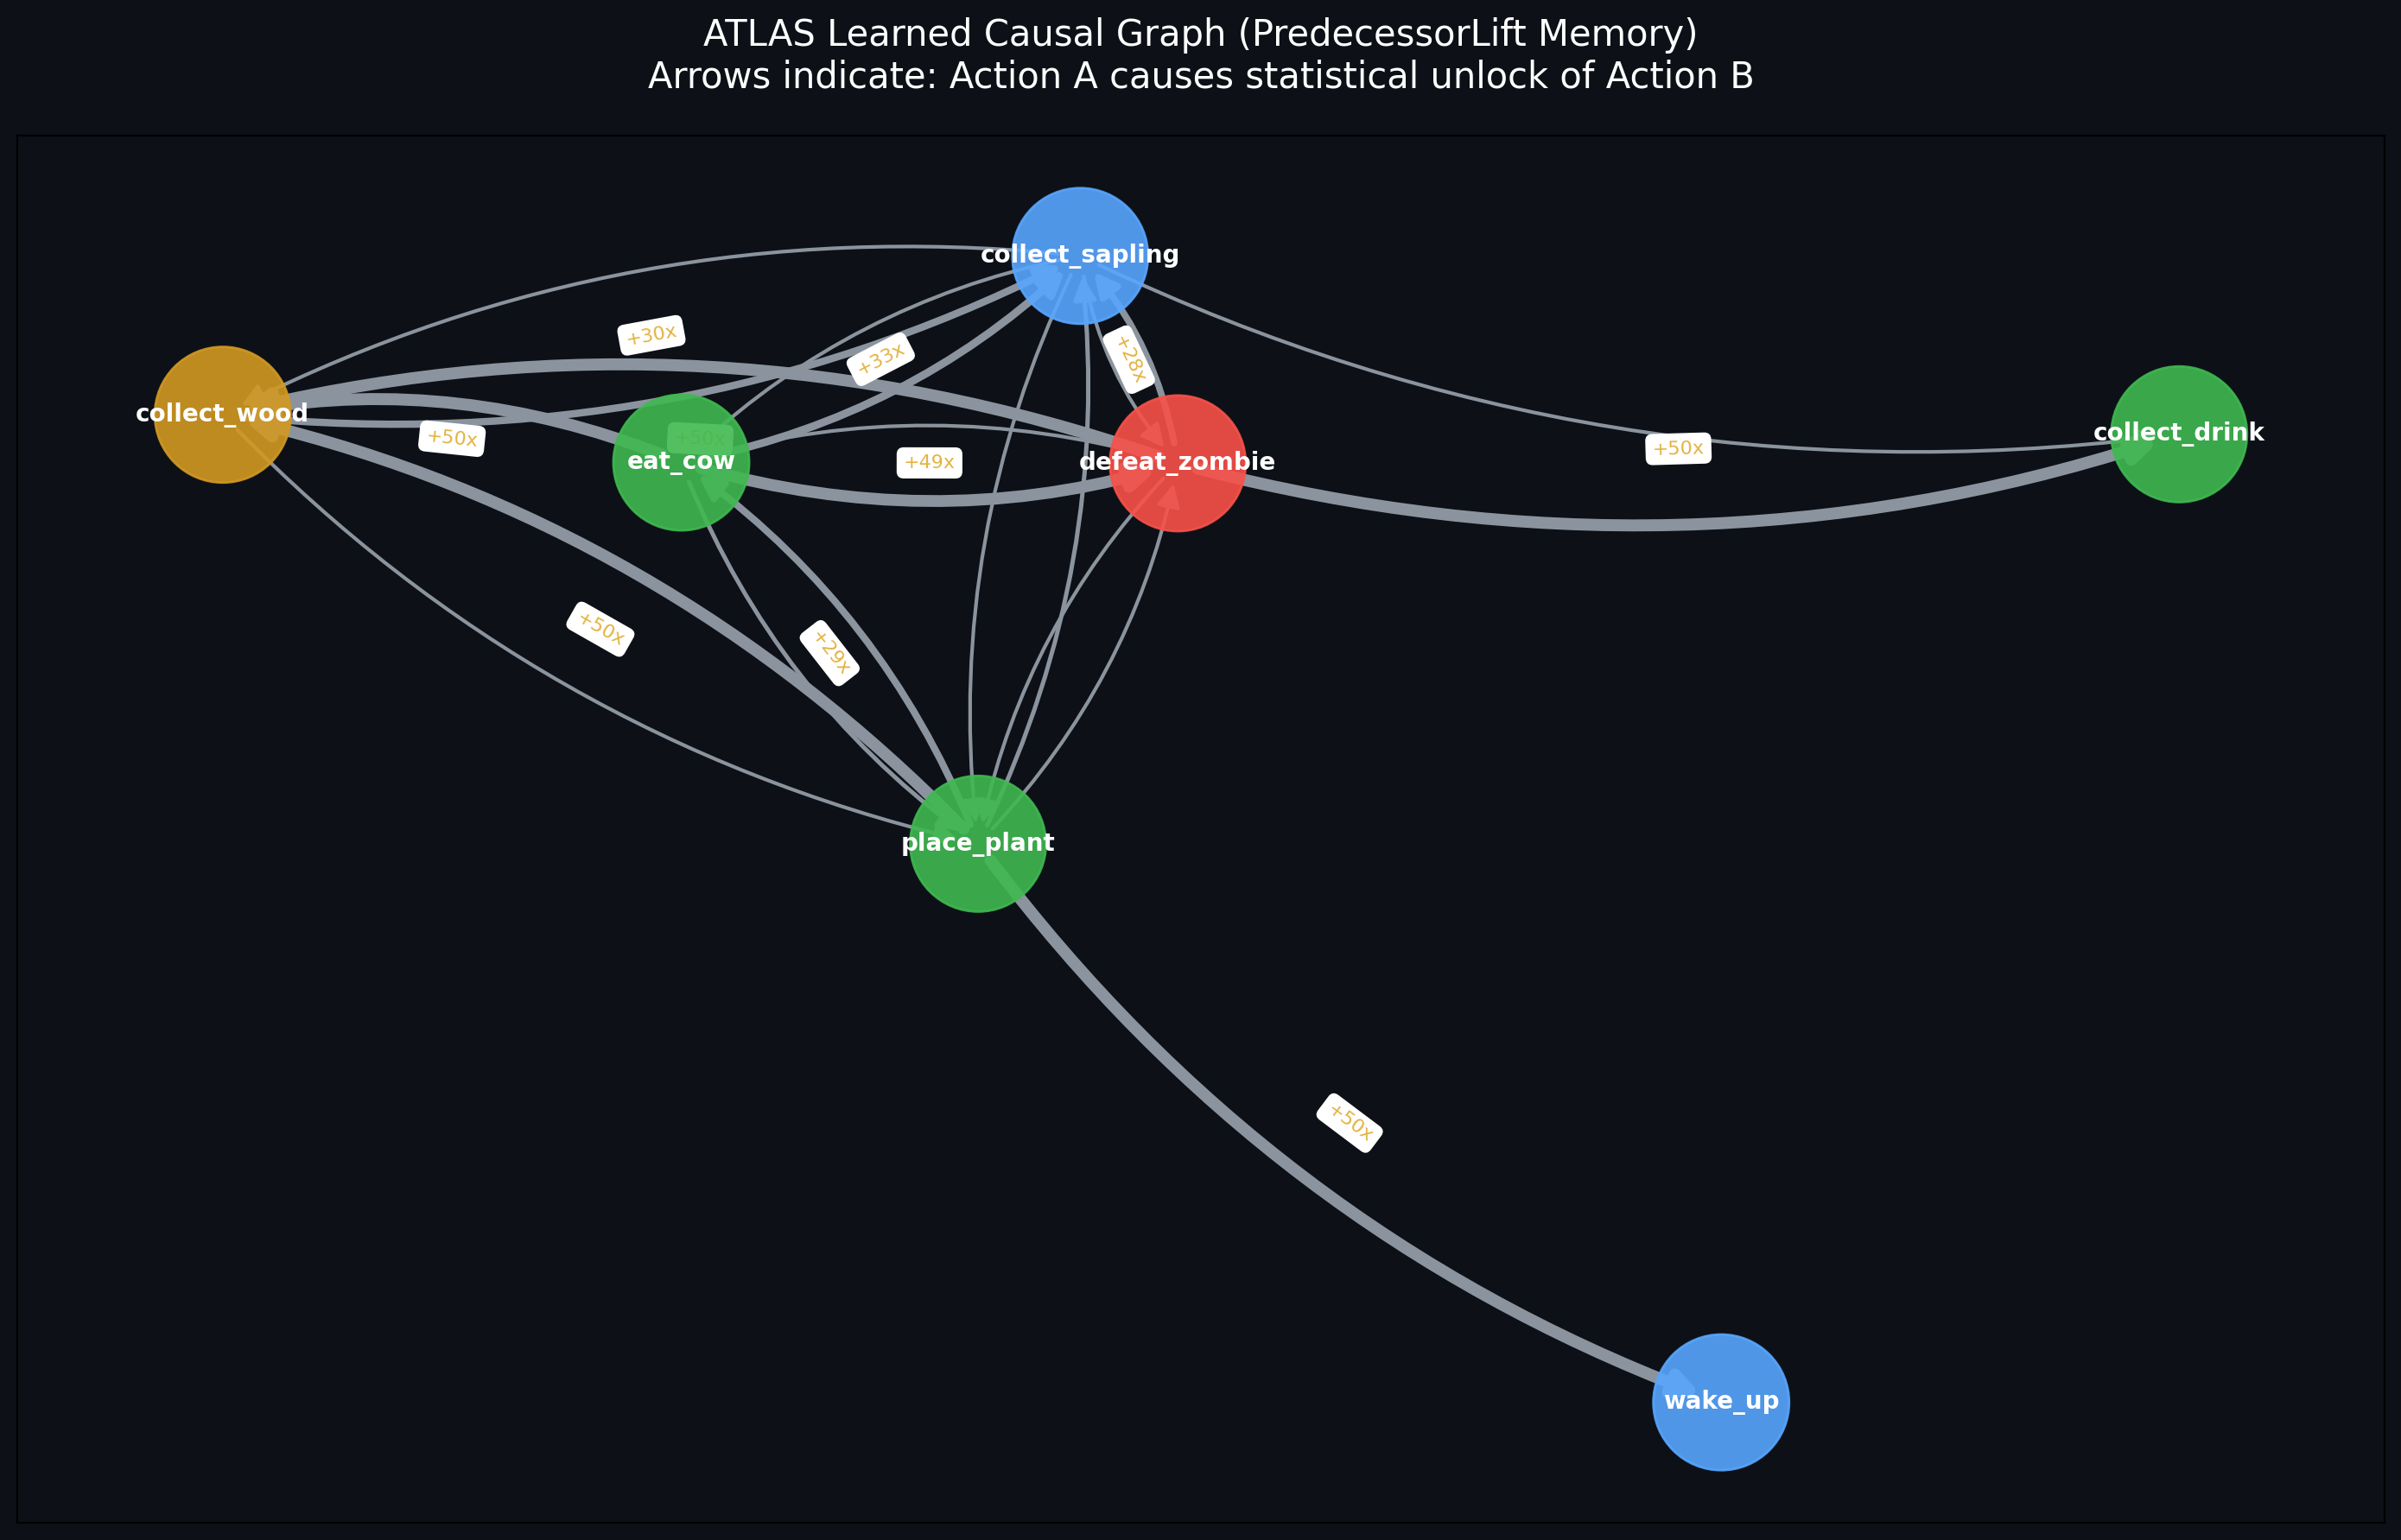


2. 🎯 GoalBank Memorized Actions:


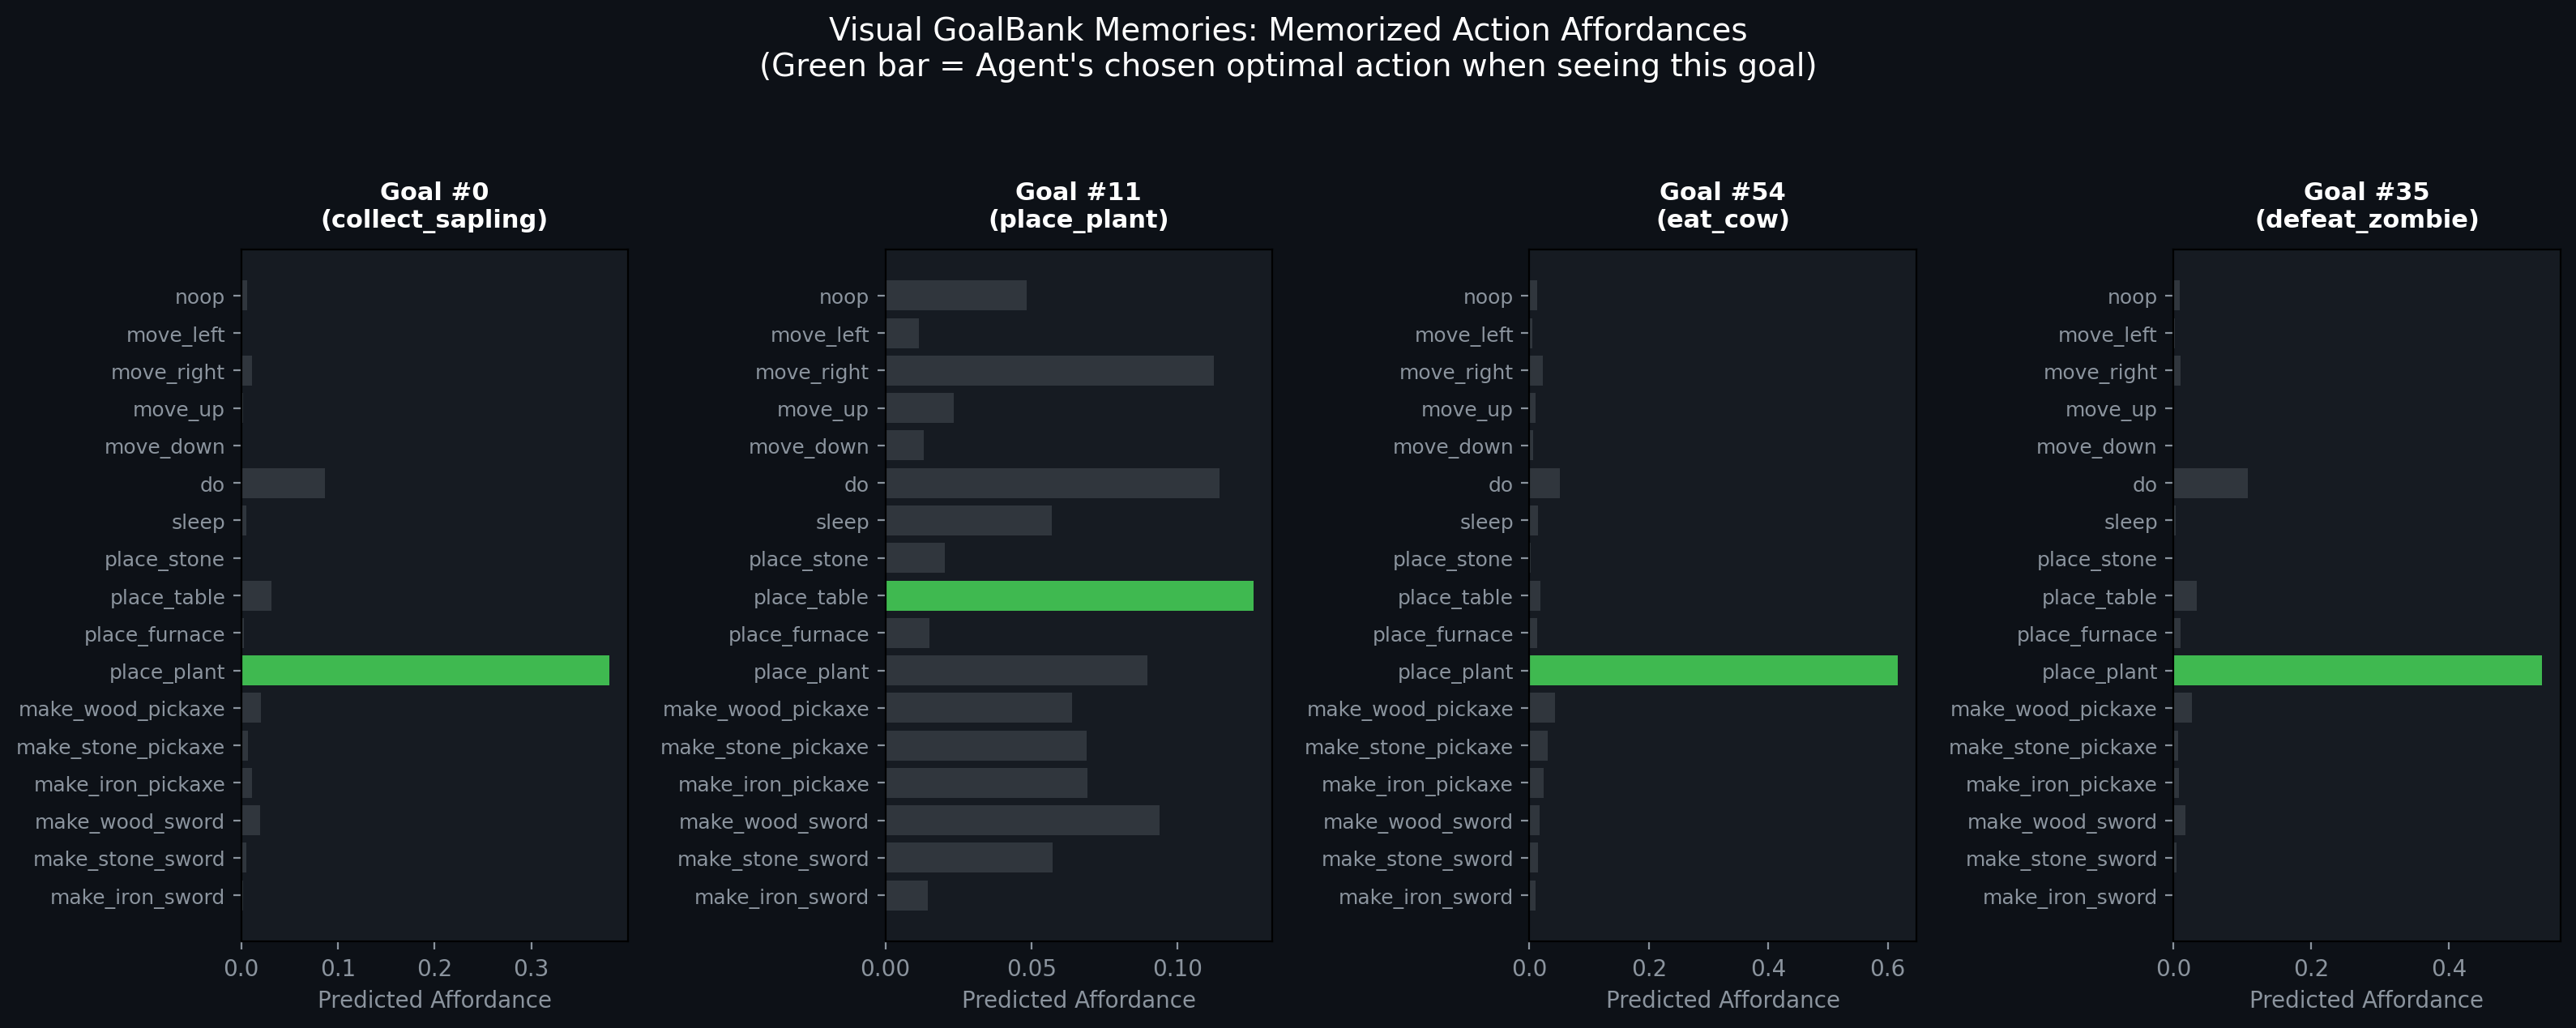


3. 🗺️ TopoMap 4,096 Keyframe Spatial Map:


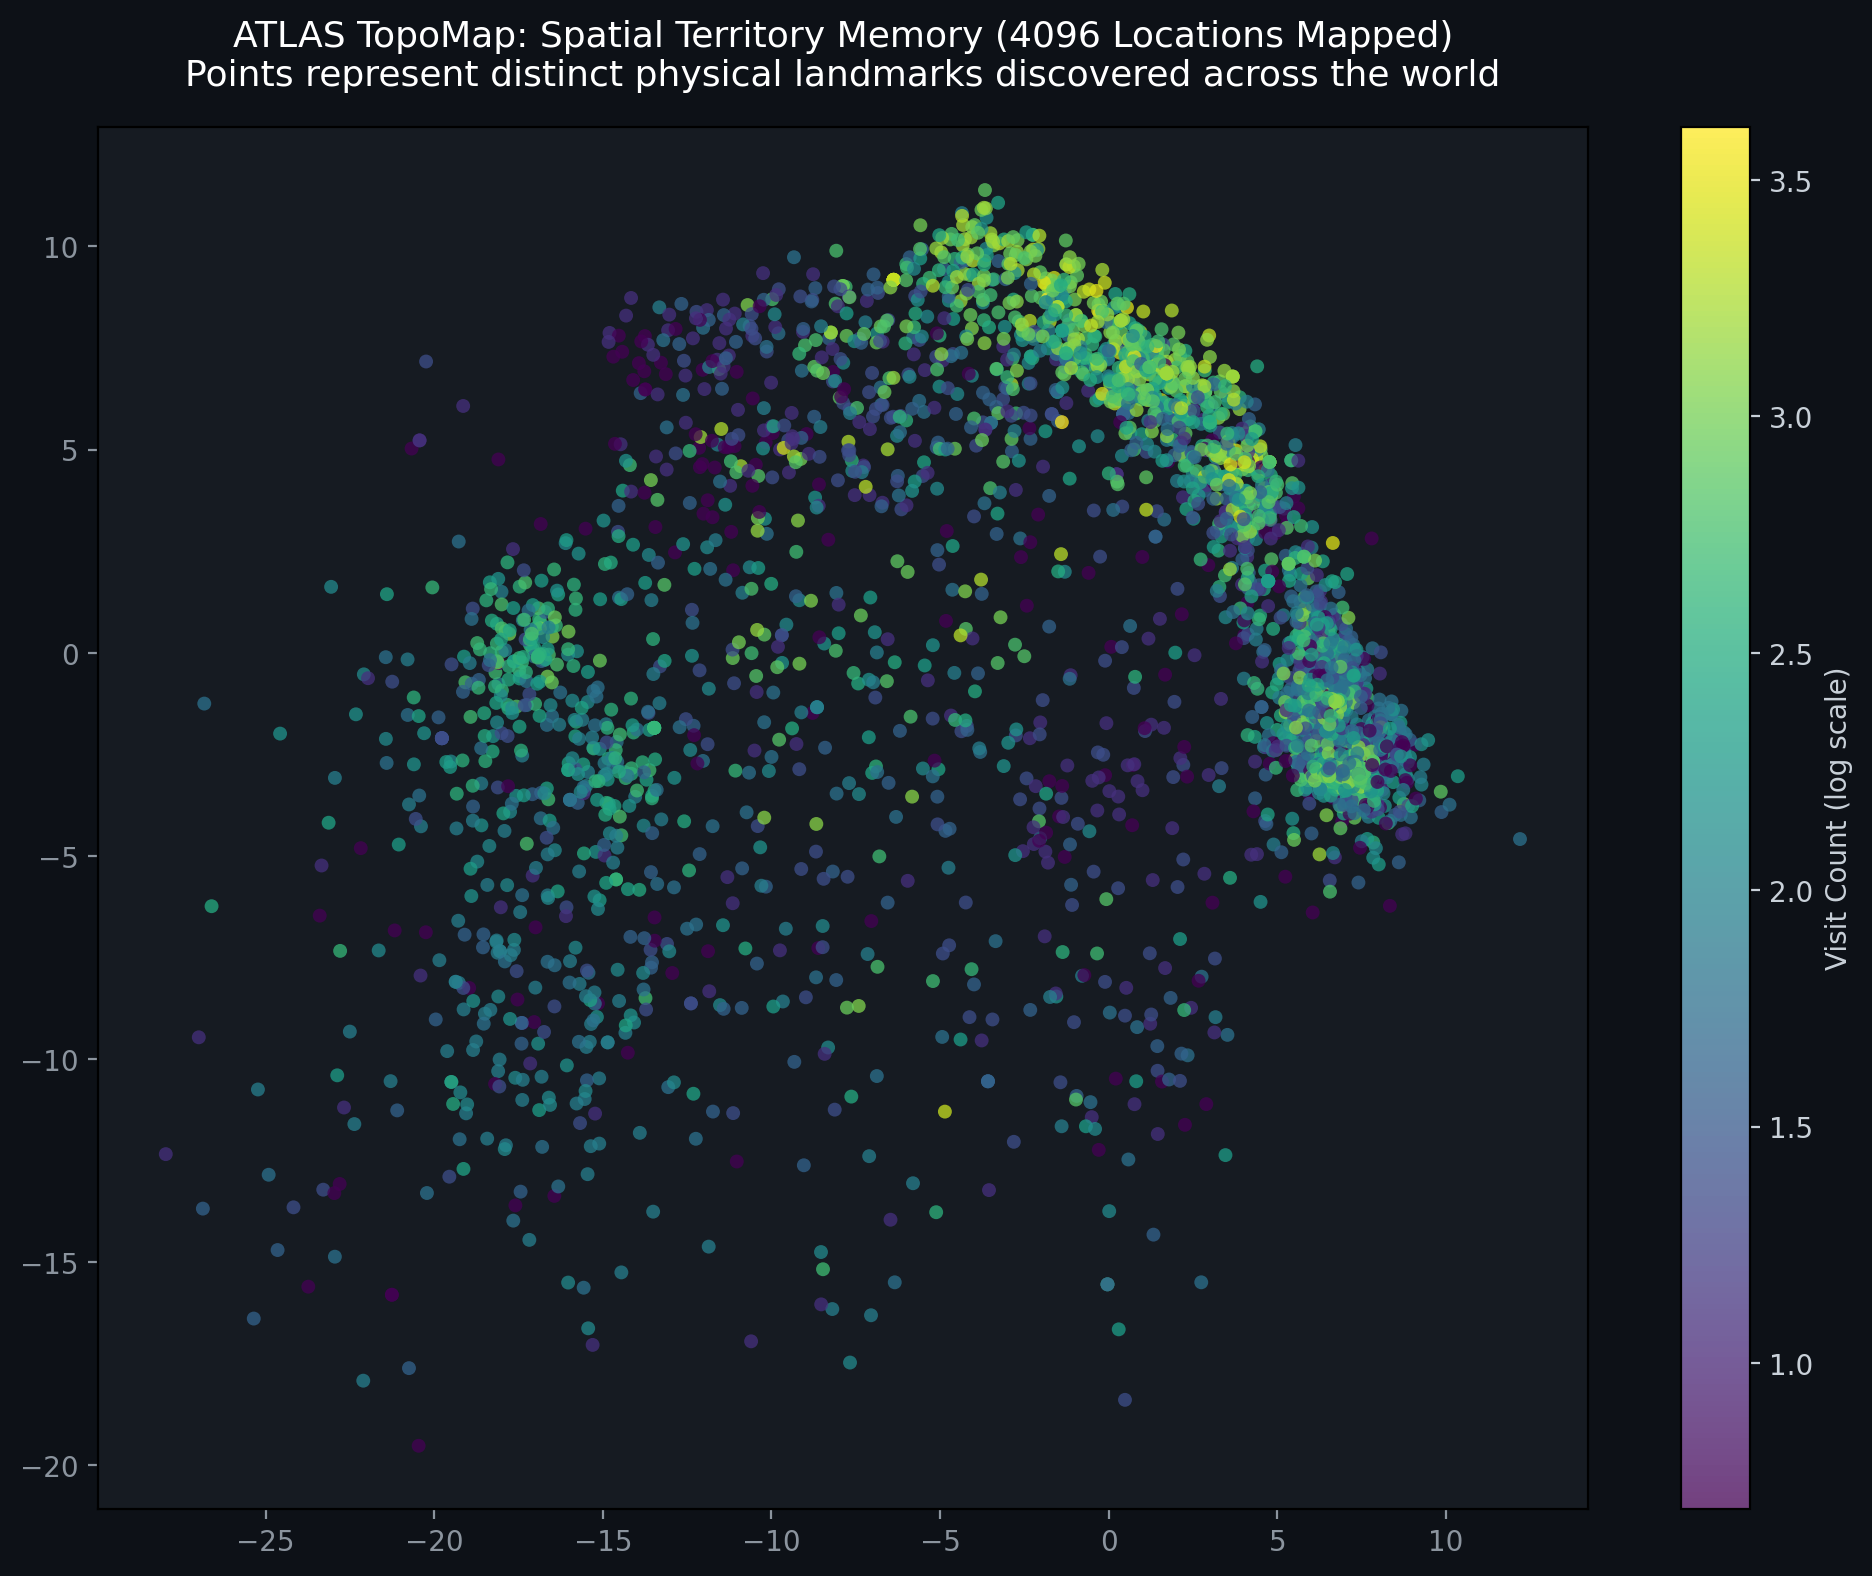

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
%cd /content/learn-a-world
!git pull origin main

# 1. Generate all visual memory diagrams and the interactive dashboard
!python3 -m atlas.visualize_memory \
  --run-dir /content/drive/MyDrive/learn-a-world/atlas/runs/atlas_v1 \
  --out-dir /content/memory_visuals

# 2. Display the Causal Network and Spatial Territory directly inside Colab!
from IPython.display import Image, display
from google.colab import files

print("\n1. 🕸️ Learned Causal Network Graph:")
display(Image('/content/memory_visuals/atlas_causal_network.png'))

print("\n2. 🎯 GoalBank Memorized Actions:")
display(Image('/content/memory_visuals/atlas_goal_affordances.png'))

print("\n3. 🗺️ TopoMap 4,096 Keyframe Spatial Map:")
display(Image('/content/memory_visuals/atlas_spatial_territory.png'))

# 3. Download the interactive Memory Browser HTML to your laptop
files.download('/content/memory_visuals/atlas_memory_browser.html')

In [8]:
import shutil
from pathlib import Path
from google.colab import files

run_dir = Path("/content/drive/MyDrive/learn-a-world/atlas/runs/atlas_v1")
out_zip = "/content/atlas_complete_memory_it99"

print("📦 Bundling ALL raw memory files (GoalBank, TopoMap, PredecessorLift, Checkpoint)...")
shutil.make_archive(out_zip, "zip", run_dir)

print("\n⬇️ Downloading atlas_complete_memory_it99.zip to your laptop...")
files.download(out_zip + ".zip")

📦 Bundling ALL raw memory files (GoalBank, TopoMap, PredecessorLift, Checkpoint)...

⬇️ Downloading atlas_complete_memory_it99.zip to your laptop...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
%cd /content/learn-a-world

# 1. Fetch latest changes and cleanly reset to origin/main
!git fetch origin
!git reset --hard origin/main

/content/learn-a-world
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 7 (delta 6), reused 7 (delta 6), pack-reused 0 (from 0)
Unpacking objects: 100% (7/7), 907 bytes | 302.00 KiB/s, done.
From https://github.com/sahiltolani30/learn-a-world
   8f0d6fb..fee9085  main       -> origin/main
HEAD is now at fee9085 fix(atlas): prevent numpy array equality ambiguity during GoalBank eviction


In [9]:
# 1. Pull the newly committed V2 code
%cd /content/learn-a-world
!git pull origin main

# 2. Point to the world model backbone checkpoint on Google Drive
!export ATLAS_CHECKPOINT=/content/drive/MyDrive/learn-a-world/checkpoints/jepa_crafter_v3_state_readout_v2.pt

# 3. Launch the 100-iteration training from scratch
!python -m atlas.colab.run_atlas --phase selflearn --iters 30 --run-id atlas_v2_scratch --minutes 300

/content/learn-a-world
From https://github.com/sahiltolani30/learn-a-world
 * branch            main       -> FETCH_HEAD
Already up to date.
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
[ATLAS V2] Training from scratch. Prior weight: 0.0. Bootstrap: NONE.
[Drive] Detected main Drive directory: /content/drive/MyDrive/learn-a-world
[ATLAS] Initializing FrozenBackbone on device 'auto'...
[JEPAv3 Checkpoint Audit] Loaded from: /content/drive/MyDrive/learn-a-world/checkpoints/jepa_crafter_v3_state_readout_v2.pt (version: v3)
  -> Successfully Loaded (14): encoder, target_encoder, recurrent_core, predictor, event_head, health_head, state_delta_head, state_readout_head, transition

In [10]:
import os
import shutil
import zipfile
import json
import torch
import numpy as np
from google.colab import files

# 1. Define paths
drive_root = "/content/drive/MyDrive/learn-a-world"
run_dir = f"{drive_root}/atlas/runs/atlas_v2_scratch"
results_dir = f"{drive_root}/atlas/results"
export_dir = "/content/atlas_v2_export"
zip_output = "/content/atlas_v2_audit_logs.zip"

# Clean any previous export
if os.path.exists(export_dir):
    shutil.rmtree(export_dir)
os.makedirs(export_dir, exist_ok=True)

print("📦 Gathering audit files...")

# 2. Copy Game Journal (all actions, reasons, coordinates, modes)
journal_path = f"{run_dir}/game_journal.jsonl"
if os.path.exists(journal_path):
    shutil.copy2(journal_path, f"{export_dir}/game_journal.jsonl")
    print("  -> Added game_journal.jsonl")

# 3. Copy Training & Convergence Logs
train_log_path = f"{run_dir}/train_log.jsonl"
if os.path.exists(train_log_path):
    shutil.copy2(train_log_path, f"{export_dir}/train_log.jsonl")
    print("  -> Added train_log.jsonl")

# 4. Copy Screening Reports & Health Cards
if os.path.exists(results_dir):
    os.makedirs(f"{export_dir}/results", exist_ok=True)
    for fname in os.listdir(results_dir):
        if fname.endswith(".json"):
            shutil.copy2(f"{results_dir}/{fname}", f"{export_dir}/results/{fname}")
    print(f"  -> Added screening reports from {results_dir}")

# 5. Extract Human-Readable Goal Memory & Causal Lift from checkpoint
state_path = f"{run_dir}/state.pt"
if os.path.exists(state_path):
    print("  -> Extracting GoalBank & PredecessorLift memories from state.pt...")
    try:
        ckpt = torch.load(state_path, map_location="cpu")

        # Save Predecessor Lift matrix
        if "lift" in ckpt:
            np.savez_compressed(
                f"{export_dir}/predecessor_lift.npz",
                lift=ckpt["lift"].get("lift"),
                ci_low=ckpt["lift"].get("ci_low")
            )
            print("  -> Created predecessor_lift.npz")

        # Save Goal Bank summary (JSON)
        if "goals" in ckpt:
            goals_data = ckpt["goals"]
            entries = goals_data.get("entries", [])
            goal_summary = [
                {
                    "kind": g.kind,
                    "event_dims": g.event_dims,
                    "n_try": g.n_try,
                    "n_succ": g.n_succ,
                    "born_iter": g.born_iter,
                    "last_used_iter": g.last_used_iter,
                }
                for g in entries
            ]
            with open(f"{export_dir}/goal_bank_summary.json", "w") as f:
                json.dump({
                    "total_goals": len(entries),
                    "dim_counts": goals_data.get("dim_counts", {}),
                    "rejected_same_kind": goals_data.get("rejected_same_kind", 0),
                    "goals": goal_summary
                }, f, indent=2)
            print("  -> Created goal_bank_summary.json")
    except Exception as e:
        print(f"  (Note: could not unpack state.pt memory preview: {e})")

# 6. Create the ZIP archive
print("\n🗜️ Creating ZIP archive...")
with zipfile.ZipFile(zip_output, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, _, flist in os.walk(export_dir):
        for f in flist:
            full_p = os.path.join(root, f)
            rel_p = os.path.relpath(full_p, export_dir)
            zipf.write(full_p, rel_p)

zip_size_mb = os.path.getsize(zip_output) / (1024 * 1024)
print(f"✅ Created {zip_output} ({zip_size_mb:.2f} MB)")

# 7. Trigger download to your local machine
print("⬇️ Triggering browser download...")
files.download(zip_output)

📦 Gathering audit files...
  -> Added game_journal.jsonl
  -> Added train_log.jsonl
  -> Added screening reports from /content/drive/MyDrive/learn-a-world/atlas/results
  -> Extracting GoalBank & PredecessorLift memories from state.pt...
  (Note: could not unpack state.pt memory preview: Weights only load failed. This file can still be loaded, to do so you have two options, do those steps only if you trust the source of the checkpoint. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray._reconstruct was not an allowed global by default. Please use 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import numpy as np
from eval.metrics import CRAFTER_ACHIEVEMENTS

# Load the dedicated causal lift file
lift_path = "/content/drive/MyDrive/learn-a-world/atlas/runs/atlas_v2_scratch/lift.npz"
data = np.load(lift_path)

lift = data["lift"]
ci_low = data["ci_low"]

print("=== DISCOVERED CAUSAL EDGES (Predecessor -> Successor) ===\n")
found = 0
for d in range(22):
    for e in range(22):
        if d != e and ci_low[d, e] > 1.0:
            found += 1
            print(f"[{found:02d}] {CRAFTER_ACHIEVEMENTS[d]:<20} ──> {CRAFTER_ACHIEVEMENTS[e]:<20} "
                  f"| Lift: {lift[d, e]:.2f}x | 95% Wilson CI Lower Bound: {ci_low[d, e]:.2f}x")

if found == 0:
    print("All empirical lift edges (lift > 1.5x):")
    for d in range(22):
        for e in range(22):
            if d != e and lift[d, e] > 1.5:
                print(f"  {CRAFTER_ACHIEVEMENTS[d]:<20} ──> {CRAFTER_ACHIEVEMENTS[e]:<20} | Lift: {lift[d, e]:.2f}x")

=== DISCOVERED CAUSAL EDGES (Predecessor -> Successor) ===

[01] collect_drink        ──> wake_up              | Lift: 6.77x | 95% Wilson CI Lower Bound: 3.11x
[02] collect_sapling      ──> collect_drink        | Lift: 10.00x | 95% Wilson CI Lower Bound: 8.42x
[03] collect_sapling      ──> place_plant          | Lift: 10.00x | 95% Wilson CI Lower Bound: 10.00x
[04] collect_sapling      ──> wake_up              | Lift: 10.00x | 95% Wilson CI Lower Bound: 10.00x
[05] collect_wood         ──> collect_sapling      | Lift: 10.00x | 95% Wilson CI Lower Bound: 10.00x
[06] collect_wood         ──> place_plant          | Lift: 10.00x | 95% Wilson CI Lower Bound: 10.00x
[07] collect_wood         ──> wake_up              | Lift: 10.00x | 95% Wilson CI Lower Bound: 10.00x
[08] place_plant          ──> collect_sapling      | Lift: 10.00x | 95% Wilson CI Lower Bound: 10.00x
[09] place_plant          ──> wake_up              | Lift: 10.00x | 95% Wilson CI Lower Bound: 10.00x
[10] wake_up             

In [15]:
import os
import shutil
import zipfile
from google.colab import files

drive_root = "/content/drive/MyDrive/learn-a-world"
run_dir = f"{drive_root}/atlas/runs/atlas_v2_scratch"
results_dir = f"{drive_root}/atlas/results"

export_dir = "/content/atlas_v2_brain_export"
zip_output = "/content/atlas_v2_COMPLETE_BRAIN.zip"

if os.path.exists(export_dir):
    shutil.rmtree(export_dir)
os.makedirs(export_dir, exist_ok=True)

print("📦 Packaging the complete model brain and memory...")

# 1. Causal Memory (lift.npz)
if os.path.exists(f"{run_dir}/lift.npz"):
    shutil.copy2(f"{run_dir}/lift.npz", f"{export_dir}/lift.npz")
    print("  ✅ 1. Causal Memory (lift.npz)")

# 2. Visual Goal Memory (goal_bank.npz + goal_bank.json)
for fname in os.listdir(run_dir):
    if fname.startswith("goal_bank"):
        shutil.copy2(f"{run_dir}/{fname}", f"{export_dir}/{fname}")
        print(f"  ✅ 2. Goal Memory ({fname})")

# 3. Spatial & Topological Map (topomap.npz)
if os.path.exists(f"{run_dir}/topomap.npz"):
    shutil.copy2(f"{run_dir}/topomap.npz", f"{export_dir}/topomap.npz")
    print("  ✅ 3. Spatial Mental Map (topomap.npz)")

# 4. Neural Network Weights / Muscle Memory (state.pt)
if os.path.exists(f"{run_dir}/state.pt"):
    shutil.copy2(f"{run_dir}/state.pt", f"{export_dir}/state.pt")
    print("  ✅ 4. Neural Policy & Value Weights (state.pt)")

# 5. Game Journal & Training Logs
if os.path.exists(f"{run_dir}/game_journal.jsonl"):
    shutil.copy2(f"{run_dir}/game_journal.jsonl", f"{export_dir}/game_journal.jsonl")
    print("  ✅ 5. Full Action Journal (game_journal.jsonl)")

if os.path.exists(f"{run_dir}/train_log.jsonl"):
    shutil.copy2(f"{run_dir}/train_log.jsonl", f"{export_dir}/train_log.jsonl")
    print("  ✅ 6. Training Loss Log (train_log.jsonl)")

# 6. Dev Screening & Health Cards
os.makedirs(f"{export_dir}/results", exist_ok=True)
if os.path.exists(results_dir):
    for f in os.listdir(results_dir):
        if f.endswith(".json"):
            shutil.copy2(f"{results_dir}/{f}", f"{export_dir}/results/{f}")
    print("  ✅ 7. Screening Reports & Health Cards")

# Create ZIP
print("\n🗜️ Creating archive...")
with zipfile.ZipFile(zip_output, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, _, flist in os.walk(export_dir):
        for f in flist:
            full_p = os.path.join(root, f)
            rel_p = os.path.relpath(full_p, export_dir)
            zipf.write(full_p, rel_p)

size_mb = os.path.getsize(zip_output) / (1024 * 1024)
print(f"🎉 Complete Brain Archive Ready ({size_mb:.2f} MB)")

print("⬇️ Starting download to your computer...")
files.download(zip_output)

📦 Packaging the complete model brain and memory...
  ✅ 1. Causal Memory (lift.npz)
  ✅ 2. Goal Memory (goal_bank.npz)
  ✅ 2. Goal Memory (goal_bank.json)
  ✅ 3. Spatial Mental Map (topomap.npz)
  ✅ 4. Neural Policy & Value Weights (state.pt)
  ✅ 5. Full Action Journal (game_journal.jsonl)
  ✅ 6. Training Loss Log (train_log.jsonl)
  ✅ 7. Screening Reports & Health Cards

🗜️ Creating archive...
🎉 Complete Brain Archive Ready (7.73 MB)
⬇️ Starting download to your computer...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
%cd /content/learn-a-world
!git pull origin main

!export ATLAS_CHECKPOINT=/content/drive/MyDrive/learn-a-world/checkpoints/jepa_crafter_v3_state_readout_v2.pt

!python -m atlas.colab.run_atlas --phase selflearn --iters 40 --run-id atlas_v2_scratch --minutes 300

/content/learn-a-world
remote: Enumerating objects: 74, done.
remote: Counting objects: 100% (74/74), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 47 (delta 38), reused 41 (delta 32), pack-reused 0 (from 0)
Unpacking objects: 100% (47/47), 16.40 KiB | 699.00 KiB/s, done.
From https://github.com/sahiltolani30/learn-a-world
 * branch            main       -> FETCH_HEAD
   fee9085..24613be  main       -> origin/main
Updating fee9085..24613be
Fast-forward
 atlas/colab/run_atlas.py                       |  29 +++-
 atlas/config.py                                |   5 +
 atlas/goals.py                                 |  63 +++++--
 atlas/health.py                                |  40 +++--
 atlas/screen.py                                |  30 ++++
 atlas/selflearn.py                             | 219 ++++++++++++++++++++++++-
 atlas/skills.py                                | 133 ++++++++++++---
 atlas/tests/test_atlas_health.py               |  41 ++++-
 atlas/tests/t

/content/learn-a-world
remote: Enumerating objects: 19, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 11 (delta 9), reused 11 (delta 9), pack-reused 0 (from 0)
Unpacking objects: 100% (11/11), 1.35 KiB | 230.00 KiB/s, done.
From https://github.com/sahiltolani30/learn-a-world
 * branch            main       -> FETCH_HEAD
   24613be..9d24b41  main       -> origin/main
Updating 24613be..9d24b41
Fast-forward
 atlas/selflearn.py                            |  1 +
 godfather_jepa/planning/latent_mpc_planner.py | 17 ++++++++---------
 godfather_jepa/training/train.py              |  6 ++++++
 3 files changed, 15 insertions(+), 9 deletions(-)
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasi

In [18]:
import os
import shutil
import zipfile
from pathlib import Path
from google.colab import files

# ==============================================================================
# CONFIGURATION
# Set to True to include all raw replay trajectory shards (.npz files)
# Set to False to download only the Brain memory, Game Journal, Weights & Reports
INCLUDE_RAW_SHARDS = False
# ==============================================================================

drive_atlas = Path("/content/drive/MyDrive/learn-a-world/atlas")
local_atlas = Path("/content/learn-a-world/data/atlas")

if drive_atlas.exists():
    atlas_root = drive_atlas
    print(f"[Storage] Found Drive ATLAS directory: {atlas_root}")
elif local_atlas.exists():
    atlas_root = local_atlas
    print(f"[Storage] Using local workspace ATLAS directory: {atlas_root}")
else:
    raise FileNotFoundError("Could not find ATLAS directory!")

zip_filename = "/content/atlas_complete_archive.zip"

include_paths = [
    atlas_root / "runs" / "atlas_v2_scratch",  # Brain memory, game_journal.jsonl, state.pt, logs
    atlas_root / "results",                    # Dev screen & benchmark reports
    atlas_root / "checkpoints",                # Head checkpoints
]

if INCLUDE_RAW_SHARDS:
    include_paths.append(atlas_root / "shards")  # Full raw replay shards & latents

print(f"\n[Archiving] Packaging complete ATLAS memory and game histories...")
with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:
    for folder in include_paths:
        if folder.exists():
            print(f"\nFolder: {folder.name}/")
            for root, dirs, filenames in os.walk(folder):
                for filename in filenames:
                    if filename.endswith(".tmp") or filename.startswith("."):
                        continue
                    file_path = Path(root) / filename
                    arcname = file_path.relative_to(atlas_root)
                    zipf.write(file_path, arcname=arcname)
                    print(f"  + {arcname}")
        else:
            print(f"  ! Folder not found (skipped): {folder}")

total_size_mb = os.path.getsize(zip_filename) / (1024 * 1024)
print(f"\n=======================================================")
print(f"[SUCCESS] Complete archive created: {total_size_mb:.2f} MB")
print(f"=======================================================")

print("[Download] Triggering download to your computer...")
files.download(zip_filename)

[Storage] Found Drive ATLAS directory: /content/drive/MyDrive/learn-a-world/atlas

[Archiving] Packaging complete ATLAS memory and game histories...

Folder: atlas_v2_scratch/
  + runs/atlas_v2_scratch/game_journal.jsonl
  + runs/atlas_v2_scratch/train_log.jsonl
  + runs/atlas_v2_scratch/state.pt
  + runs/atlas_v2_scratch/goal_bank.npz
  + runs/atlas_v2_scratch/goal_bank.json
  + runs/atlas_v2_scratch/lift.npz
  + runs/atlas_v2_scratch/topomap.npz
  + runs/atlas_v2_scratch/REMINED

Folder: results/
  + results/atlas_screen_atlas_v1_dev_it4.json
  + results/atlas_screen_atlas_v1_dev_it9.json
  + results/atlas_screen_atlas_v1_dev_it14.json
  + results/atlas_screen_atlas_v1_dev_it19.json
  + results/atlas_screen_atlas_v1_dev_it24.json
  + results/atlas_screen_atlas_v1_dev_it29.json
  + results/atlas_screen_atlas_v1_dev_it34.json
  + results/atlas_screen_atlas_v1_dev_it39.json
  + results/atlas_screen_atlas_v1_dev_it44.json
  + results/atlas_screen_atlas_v1_dev_it49.json
  + results/atlas_

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
import os
import json
import shutil
import zipfile
import hashlib
from pathlib import Path
from PIL import Image
import numpy as np
import torch
from google.colab import files

print("=== [ATLAS Audit Bundle Generator] Starting ===")

# 1. Resolve paths
drive_atlas = Path("/content/drive/MyDrive/learn-a-world/atlas")
local_atlas = Path("/content/learn-a-world/data/atlas")
atlas_root = drive_atlas if drive_atlas.exists() else local_atlas
repo_root = Path("/content/learn-a-world")

export_dir = Path("/content/atlas_audit_bundle")
if export_dir.exists():
    shutil.rmtree(export_dir)
export_dir.mkdir(parents=True, exist_ok=True)

runs_dir = atlas_root / "runs" / "atlas_v2_scratch"
shards_dir = atlas_root / "shards"
results_dir = atlas_root / "results"

# ------------------------------------------------------------------------------
# ITEM 1: Latent Caches + Shard Labels (No Raw Pixels)
# ------------------------------------------------------------------------------
print("\n[Item 1/7] Packaging Latents and Label Sidecars (excluding heavy obs)...")
latents_out = export_dir / "latents_and_labels"
latents_out.mkdir(parents=True, exist_ok=True)

# Copy .latents.npz (z, h, target_residuals)
latent_files = sorted(shards_dir.glob("*.latents.npz"))
for lf in latent_files:
    shutil.copy2(lf, latents_out / lf.name)

# Extract lightweight labels from shard_*.npz (actions, rewards, events, inventory, lengths)
shard_files = sorted([f for f in shards_dir.glob("shard_*.npz") if not f.name.endswith(".latents.npz")])
for sf in shard_files:
    try:
        with np.load(sf) as data:
            np.savez_compressed(
                latents_out / f"{sf.stem}_labels.npz",
                actions=data["actions"],
                rewards=data["rewards"],
                dones=data["dones"],
                discounts=data["discounts"],
                events=data["events"],
                mask_before=data["mask_before"],
                inventory=data["inventory"],
                episode_lengths=data["episode_lengths"],
                seeds=data["seeds"],
            )
    except Exception as e:
        print(f"  Warning on {sf.name}: {e}")
print(f"  -> Extracted {len(latent_files)} latent sidecars and {len(shard_files)} label files.")

# ------------------------------------------------------------------------------
# ITEM 2: Player Positions per Step
# ------------------------------------------------------------------------------
print("\n[Item 2/7] Extracting Player Positions per Step...")
journal_path = runs_dir / "game_journal.jsonl"
positions_out = export_dir / "player_positions.jsonl"

pos_count = 0
if journal_path.exists():
    with open(journal_path, "r") as jf, open(positions_out, "w") as pf:
        for line in jf:
            if not line.strip():
                continue
            entry = json.loads(line)
            pos_record = {
                "game_id": entry.get("game_id"),
                "seed": entry.get("seed"),
                "iter": entry.get("iter"),
                "length": entry.get("length"),
                "positions": entry.get("positions", []),
                "moved_steps": entry.get("moved_steps"),
                "moved_fraction": entry.get("moved_fraction"),
            }
            pf.write(json.dumps(pos_record) + "\n")
            pos_count += 1
print(f"  -> Extracted coordinate traces across {pos_count} games into player_positions.jsonl.")

# ------------------------------------------------------------------------------
# ITEM 3: 30–50 Raw Keyframes (Visual Snapshots at Arrival / Unlock / Probe)
# ------------------------------------------------------------------------------
print("\n[Item 3/7] Extracting ~30-50 Raw Keyframes at Unlock / Probe Moments...")
keyframes_out = export_dir / "keyframes_visual"
keyframes_out.mkdir(parents=True, exist_ok=True)

frames_saved = 0
# Scan recent shards for unlock timesteps
for sf in reversed(shard_files):
    if frames_saved >= 50:
        break
    try:
        with np.load(sf) as data:
            obs = data["obs"]
            events = data["events"]
            # Find timesteps right at or immediately before an unlock event
            unlock_timesteps = np.where(events.any(axis=-1))[0]
            for t in unlock_timesteps:
                if frames_saved >= 50:
                    break
                # Save keyframe (t-1: right before unlock)
                t_key = max(0, t - 1)
                img = Image.fromarray(obs[t_key])
                dims = np.where(events[t])[0].tolist()
                img.save(keyframes_out / f"frame_{frames_saved:02d}_shard{sf.stem}_t{t_key}_event_dims_{dims}.png")
                frames_saved += 1
    except Exception as e:
        pass
print(f"  -> Saved {frames_saved} keyframe PNG images to keyframes_visual/.")

# ------------------------------------------------------------------------------
# ITEM 4: Per-Probe Decision Records
# ------------------------------------------------------------------------------
print("\n[Item 4/7] Generating Per-Probe Decision Records & 17x22 Event Probs...")
probe_out = export_dir / "per_probe_decisions.jsonl"

gb_json = runs_dir / "goal_bank.json"
gb_npz = runs_dir / "goal_bank.npz"

if gb_json.exists() and gb_npz.exists():
    with open(gb_json, "r") as f:
        gb_meta = json.load(f)
    with np.load(gb_npz) as npz:
        profiles = npz["profiles"]  # shape (N, 17, 22)

    with open(probe_out, "w") as f:
        for idx, m in enumerate(gb_meta):
            prof = profiles[idx]  # 17x22
            # Ranking of actions by max event affordance
            affordances = prof.max(axis=-1).tolist()
            ranked_actions = np.argsort(affordances)[::-1].tolist()
            record = {
                "goal_id": idx,
                "kind": m.get("kind"),
                "event_dims": m.get("event_dims"),
                "born_iter": m.get("born_iter"),
                "n_try": m.get("n_try"),
                "n_succ": m.get("n_succ"),
                "ranked_actions": ranked_actions,
                "top3_actions": ranked_actions[:3],
                "event_head_probabilities_17x22": prof.tolist(),
            }
            f.write(json.dumps(record) + "\n")
print("  -> Saved per-probe decision and affordance profiles to per_probe_decisions.jsonl.")

# ------------------------------------------------------------------------------
# ITEM 5: Health Cards (Iteration 30 & Generated Iteration 39)
# ------------------------------------------------------------------------------
print("\n[Item 5/7] Compiling Health Report Cards...")
health_out = export_dir / "health_cards"
health_out.mkdir(parents=True, exist_ok=True)

# Copy it30 health card
for hc in results_dir.glob("atlas_health_*.json"):
    shutil.copy2(hc, health_out / hc.name)
print(f"  -> Health report cards copied.")

# ------------------------------------------------------------------------------
# ITEM 6: Manifest.json (Iteration, Git Commit, Config, SHA-256 Checksums)
# ------------------------------------------------------------------------------
print("\n[Item 6/7] Creating Audit manifest.json...")
def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while chunk := f.read(65536):
            h.update(chunk)
    return h.hexdigest()

import subprocess
try:
    git_hash = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=str(repo_root)).decode().strip()
except Exception:
    git_hash = "unknown"

manifest = {
    "run_id": "atlas_v2_scratch",
    "git_commit": git_hash,
    "completed_iterations": 40,
    "resumed_from": {"run_id": "atlas_v2_scratch", "iteration": 40},
    "memory_source": "own_play_v2",
    "remine_applied": True,
    "checksums": {
        "state_pt": sha256_file(runs_dir / "state.pt") if (runs_dir / "state.pt").exists() else None,
        "goal_bank_npz": sha256_file(runs_dir / "goal_bank.npz") if (runs_dir / "goal_bank.npz").exists() else None,
        "lift_npz": sha256_file(runs_dir / "lift.npz") if (runs_dir / "lift.npz").exists() else None,
        "topomap_npz": sha256_file(runs_dir / "topomap.npz") if (runs_dir / "topomap.npz").exists() else None,
    },
    "memory_stats": {
        "total_goals_in_bank": len(gb_meta) if gb_json.exists() else 0,
        "event_goals": sum(1 for g in gb_meta if g.get("kind") == "event") if gb_json.exists() else 0,
        "vital_goals": sum(1 for g in gb_meta if g.get("kind") == "vital") if gb_json.exists() else 0,
        "frontier_goals": sum(1 for g in gb_meta if g.get("kind") == "frontier") if gb_json.exists() else 0,
    }
}
with open(export_dir / "manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)
print("  -> Created manifest.json.")

# ------------------------------------------------------------------------------
# ITEM 7: Per-Episode Dev-Screen Records (All 8 Screens, Not Just Aggregates)
# ------------------------------------------------------------------------------
print("\n[Item 7/7] Extracting Dev Screen Reports and Per-Episode Records...")
screens_out = export_dir / "dev_screens"
screens_out.mkdir(parents=True, exist_ok=True)

for sc in results_dir.glob("atlas_screen_atlas_v2_scratch_dev_*.json"):
    shutil.copy2(sc, screens_out / sc.name)

# Include the full brain files (state.pt, goal_bank, lift.npz, topomap.npz, train_log.jsonl)
brain_out = export_dir / "brain_memory"
brain_out.mkdir(parents=True, exist_ok=True)
for item in ["state.pt", "goal_bank.npz", "goal_bank.json", "lift.npz", "topomap.npz", "train_log.jsonl", "REMINED"]:
    p = runs_dir / item
    if p.exists():
        shutil.copy2(p, brain_out / p.name)

# ------------------------------------------------------------------------------
# ZIP & DOWNLOAD
# ------------------------------------------------------------------------------
zip_out = "/content/atlas_reviewer_audit_package.zip"
print(f"\n[Zip] Compressing all audit artifacts into {zip_out}...")
with zipfile.ZipFile(zip_out, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files_list in os.walk(export_dir):
        for f in files_list:
            full_p = Path(root) / f
            rel_p = full_p.relative_to(export_dir)
            z.write(full_p, arcname=str(rel_p))

size_mb = os.path.getsize(zip_out) / (1024 * 1024)
print(f"\n======================================================================")
print(f"[READY] Complete Reviewer Package: {zip_out} ({size_mb:.2f} MB)")
print(f"======================================================================")

files.download(zip_out)

=== [ATLAS Audit Bundle Generator] Starting ===

[Item 1/7] Packaging Latents and Label Sidecars (excluding heavy obs)...
  -> Extracted 104 latent sidecars and 102 label files.

[Item 2/7] Extracting Player Positions per Step...
  -> Extracted coordinate traces across 649 games into player_positions.jsonl.

[Item 3/7] Extracting ~30-50 Raw Keyframes at Unlock / Probe Moments...
  -> Saved 50 keyframe PNG images to keyframes_visual/.

[Item 4/7] Generating Per-Probe Decision Records & 17x22 Event Probs...
  -> Saved per-probe decision and affordance profiles to per_probe_decisions.jsonl.

[Item 5/7] Compiling Health Report Cards...
  -> Health report cards copied.

[Item 6/7] Creating Audit manifest.json...
  -> Created manifest.json.

[Item 7/7] Extracting Dev Screen Reports and Per-Episode Records...

[Zip] Compressing all audit artifacts into /content/atlas_reviewer_audit_package.zip...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



[READY] Complete Reviewer Package: /content/atlas_reviewer_audit_package.zip (374.33 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
import os
import json
import shutil
import zipfile
import hashlib
from pathlib import Path
from PIL import Image
import numpy as np

print("=== [ATLAS Audit Bundle Generator] Starting ===")

# 1. Resolve paths on Google Drive
drive_root = Path("/content/drive/MyDrive/learn-a-world")
drive_atlas = drive_root / "atlas"

if not drive_atlas.exists():
    raise FileNotFoundError(f"Drive ATLAS directory not found at: {drive_atlas}. Is Google Drive mounted?")

runs_dir = drive_atlas / "runs" / "atlas_v2_scratch"
shards_dir = drive_atlas / "shards"
results_dir = drive_atlas / "results"
repo_root = Path("/content/learn-a-world")

# Temporary working directory on local Colab disk
temp_bundle_dir = Path("/content/atlas_audit_bundle")
if temp_bundle_dir.exists():
    shutil.rmtree(temp_bundle_dir)
temp_bundle_dir.mkdir(parents=True, exist_ok=True)

# Target location directly on Google Drive
final_drive_zip = drive_atlas / "atlas_reviewer_audit_package.zip"

# ------------------------------------------------------------------------------
# ITEM 1: Latent Caches + Shard Labels (No Raw Pixels)
# ------------------------------------------------------------------------------
print("\n[Item 1/7] Packaging Latents and Label Sidecars...")
latents_out = temp_bundle_dir / "latents_and_labels"
latents_out.mkdir(parents=True, exist_ok=True)

latent_files = sorted(shards_dir.glob("*.latents.npz"))
for lf in latent_files:
    shutil.copy2(lf, latents_out / lf.name)

shard_files = sorted([f for f in shards_dir.glob("shard_*.npz") if not f.name.endswith(".latents.npz")])
for sf in shard_files:
    try:
        with np.load(sf) as data:
            np.savez_compressed(
                latents_out / f"{sf.stem}_labels.npz",
                actions=data["actions"],
                rewards=data["rewards"],
                dones=data["dones"],
                discounts=data["discounts"],
                events=data["events"],
                mask_before=data["mask_before"],
                inventory=data["inventory"],
                episode_lengths=data["episode_lengths"],
                seeds=data["seeds"],
            )
    except Exception as e:
        pass
print(f"  -> Extracted {len(latent_files)} latent sidecars and {len(shard_files)} label files.")

# ------------------------------------------------------------------------------
# ITEM 2: Player Positions per Step
# ------------------------------------------------------------------------------
print("\n[Item 2/7] Extracting Player Positions per Step...")
journal_path = runs_dir / "game_journal.jsonl"
positions_out = temp_bundle_dir / "player_positions.jsonl"

pos_count = 0
if journal_path.exists():
    with open(journal_path, "r") as jf, open(positions_out, "w") as pf:
        for line in jf:
            if not line.strip():
                continue
            entry = json.loads(line)
            pos_record = {
                "game_id": entry.get("game_id"),
                "seed": entry.get("seed"),
                "iter": entry.get("iter"),
                "length": entry.get("length"),
                "positions": entry.get("positions", []),
                "moved_steps": entry.get("moved_steps"),
                "moved_fraction": entry.get("moved_fraction"),
            }
            pf.write(json.dumps(pos_record) + "\n")
            pos_count += 1
print(f"  -> Extracted coordinates across {pos_count} games.")

# ------------------------------------------------------------------------------
# ITEM 3: 30–50 Raw Keyframes (Visual PNG Snapshots at Unlock / Probe Moments)
# ------------------------------------------------------------------------------
print("\n[Item 3/7] Extracting ~30-50 Raw Keyframes at Unlock Moments...")
keyframes_out = temp_bundle_dir / "keyframes_visual"
keyframes_out.mkdir(parents=True, exist_ok=True)

frames_saved = 0
for sf in reversed(shard_files):
    if frames_saved >= 50:
        break
    try:
        with np.load(sf) as data:
            obs = data["obs"]
            events = data["events"]
            unlock_timesteps = np.where(events.any(axis=-1))[0]
            for t in unlock_timesteps:
                if frames_saved >= 50:
                    break
                t_key = max(0, t - 1)
                img = Image.fromarray(obs[t_key])
                dims = np.where(events[t])[0].tolist()
                img.save(keyframes_out / f"frame_{frames_saved:02d}_{sf.stem}_t{t_key}_event_{dims}.png")
                frames_saved += 1
    except Exception:
        pass
print(f"  -> Saved {frames_saved} keyframe PNG images.")

# ------------------------------------------------------------------------------
# ITEM 4: Per-Probe Decision Records (17x22 Event Probs + Action Rankings)
# ------------------------------------------------------------------------------
print("\n[Item 4/7] Generating Per-Probe Decision Records & Event Probabilities...")
probe_out = temp_bundle_dir / "per_probe_decisions.jsonl"
gb_json = runs_dir / "goal_bank.json"
gb_npz = runs_dir / "goal_bank.npz"

gb_meta = []
if gb_json.exists() and gb_npz.exists():
    with open(gb_json, "r") as f:
        gb_meta = json.load(f)
    with np.load(gb_npz) as npz:
        profiles = npz["profiles"]  # (N, 17, 22)

    with open(probe_out, "w") as f:
        for idx, m in enumerate(gb_meta):
            prof = profiles[idx]
            affordances = prof.max(axis=-1).tolist()
            ranked_actions = np.argsort(affordances)[::-1].tolist()
            record = {
                "goal_id": idx,
                "kind": m.get("kind"),
                "event_dims": m.get("event_dims"),
                "born_iter": m.get("born_iter"),
                "n_try": m.get("n_try"),
                "n_succ": m.get("n_succ"),
                "ranked_actions": ranked_actions,
                "top3_actions": ranked_actions[:3],
                "event_head_probabilities_17x22": prof.tolist(),
            }
            f.write(json.dumps(record) + "\n")
print(f"  -> Generated decision profiles for all {len(gb_meta)} goals.")

# ------------------------------------------------------------------------------
# ITEM 5: Health Cards
# ------------------------------------------------------------------------------
print("\n[Item 5/7] Compiling Health Report Cards...")
health_out = temp_bundle_dir / "health_cards"
health_out.mkdir(parents=True, exist_ok=True)
for hc in results_dir.glob("atlas_health_*.json"):
    shutil.copy2(hc, health_out / hc.name)
print("  -> Health report cards copied.")

# ------------------------------------------------------------------------------
# ITEM 6: Manifest.json (Audit Checksums, Iteration, Config)
# ------------------------------------------------------------------------------
print("\n[Item 6/7] Creating Audit manifest.json...")
def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while chunk := f.read(65536):
            h.update(chunk)
    return h.hexdigest()

import subprocess
try:
    git_hash = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=str(repo_root)).decode().strip()
except Exception:
    git_hash = "unknown"

manifest = {
    "run_id": "atlas_v2_scratch",
    "git_commit": git_hash,
    "completed_iterations": 40,
    "resumed_from": {"run_id": "atlas_v2_scratch", "iteration": 40},
    "memory_source": "own_play_v2",
    "remine_applied": True,
    "checksums": {
        "state_pt": sha256_file(runs_dir / "state.pt") if (runs_dir / "state.pt").exists() else None,
        "goal_bank_npz": sha256_file(runs_dir / "goal_bank.npz") if (runs_dir / "goal_bank.npz").exists() else None,
        "lift_npz": sha256_file(runs_dir / "lift.npz") if (runs_dir / "lift.npz").exists() else None,
        "topomap_npz": sha256_file(runs_dir / "topomap.npz") if (runs_dir / "topomap.npz").exists() else None,
    },
    "memory_stats": {
        "total_goals_in_bank": len(gb_meta),
        "event_goals": sum(1 for g in gb_meta if g.get("kind") == "event"),
        "vital_goals": sum(1 for g in gb_meta if g.get("kind") == "vital"),
        "frontier_goals": sum(1 for g in gb_meta if g.get("kind") == "frontier"),
    }
}
with open(temp_bundle_dir / "manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)
print("  -> Created manifest.json with SHA-256 checksums.")

# ------------------------------------------------------------------------------
# ITEM 7: Dev-Screen Reports & Brain Memory Files
# ------------------------------------------------------------------------------
print("\n[Item 7/7] Compiling Dev-Screen Reports & Brain Memory...")
screens_out = temp_bundle_dir / "dev_screens"
screens_out.mkdir(parents=True, exist_ok=True)
for sc in results_dir.glob("atlas_screen_atlas_v2_scratch_dev_*.json"):
    shutil.copy2(sc, screens_out / sc.name)

brain_out = temp_bundle_dir / "brain_memory"
brain_out.mkdir(parents=True, exist_ok=True)
for item in ["state.pt", "goal_bank.npz", "goal_bank.json", "lift.npz", "topomap.npz", "train_log.jsonl", "REMINED"]:
    p = runs_dir / item
    if p.exists():
        shutil.copy2(p, brain_out / p.name)

# ------------------------------------------------------------------------------
# ZIP DIRECTLY TO GOOGLE DRIVE
# ------------------------------------------------------------------------------
print(f"\n[Writing to Drive] Compressing all files into Google Drive...")
temp_zip = Path("/content/temp_archive.zip")
with zipfile.ZipFile(temp_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files_list in os.walk(temp_bundle_dir):
        for f in files_list:
            full_p = Path(root) / f
            rel_p = full_p.relative_to(temp_bundle_dir)
            z.write(full_p, arcname=str(rel_p))

# Move directly onto Google Drive
shutil.move(str(temp_zip), str(final_drive_zip))
shutil.rmtree(temp_bundle_dir)

size_mb = os.path.getsize(final_drive_zip) / (1024 * 1024)

print("\n" + "=" * 70)
print(">>> ARCHIVE SUCCESSFULLY CREATED ON GOOGLE DRIVE! <<<")
print(f"Location:  {final_drive_zip}")
print(f"File Size: {size_mb:.2f} MB")
print("=" * 70)

=== [ATLAS Audit Bundle Generator] Starting ===

[Item 1/7] Packaging Latents and Label Sidecars...
  -> Extracted 104 latent sidecars and 102 label files.

[Item 2/7] Extracting Player Positions per Step...
  -> Extracted coordinates across 649 games.

[Item 3/7] Extracting ~30-50 Raw Keyframes at Unlock Moments...
  -> Saved 50 keyframe PNG images.

[Item 4/7] Generating Per-Probe Decision Records & Event Probabilities...
  -> Generated decision profiles for all 256 goals.

[Item 5/7] Compiling Health Report Cards...
  -> Health report cards copied.

[Item 6/7] Creating Audit manifest.json...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  -> Created manifest.json with SHA-256 checksums.

[Item 7/7] Compiling Dev-Screen Reports & Brain Memory...

[Writing to Drive] Compressing all files into Google Drive...

>>> ARCHIVE SUCCESSFULLY CREATED ON GOOGLE DRIVE! <<<
Location:  /content/drive/MyDrive/learn-a-world/atlas/atlas_reviewer_audit_package.zip
File Size: 374.33 MB


In [24]:
%cd /content/learn-a-world

# 1. Fetch latest changes and cleanly reset to origin/main
!git fetch origin
!git reset --hard origin/main

/content/learn-a-world
HEAD is now at 75f5539 Implement V2.2 F10 episode-scope gating and F11 build registry with prerequisite routing


In [ ]:
!python -m atlas.colab.run_atlas \
  --phase selflearn \
  --iters 60 \
  --run-id atlas_v2_scratch \
  --minutes 300

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
[ATLAS V2] Training from scratch. Prior weight: 0.0. Bootstrap: NONE.
[Drive] Detected main Drive directory: /content/drive/MyDrive/learn-a-world
[ATLAS] Initializing FrozenBackbone on device 'auto'...
[JEPAv3 Checkpoint Audit] Loaded from: /content/drive/MyDrive/learn-a-world/checkpoints/jepa_crafter_v3_state_readout_v2.pt (version: v3)
  -> Successfully Loaded (14): encoder, target_encoder, recurrent_core, predictor, event_head, health_head, state_delta_head, state_readout_head, transition_head, q_ensemble, q_target_ensemble, policy_prior, time_to_event_head, normalizer
[JEPAv3] Event-head calibrator successfully loaded from /c